# Weekly forecast of the CL2/CL1 calendar spread

One notebook, run top to bottom ("Restart & Run All").

**What we forecast, and why.** A trader who holds a calendar spread (long CL2, short CL1) earns the *change* in the spread, not its level.
So the target is next week's change in carry, where carry = 100 × (CL2/CL1 − 1) and positive means contango. We use the roll-adjusted
change: the raw Friday-to-Friday change jumps every month when the front contract expires, and a position cannot earn that jump (Section 1.3).

**Why weekly.** The fundamentals in the file (stocks, production, rigs, positioning) are weekly, and the inventory report is what the curve
reacts to. Daily data would leave most days with no new information. Monthly data would leave about 350 observations instead of 1,539, and every
monthly change would contain a contract switch.

**Why carry in % and not in dollars.** A $1 spread is a big contango at $20 oil and a small one at $100 oil, and the sample has both.
The cost is that the percentage becomes extreme when CL1 is very low (April 2020), so Section 8.3 repeats the test in dollars.

| Section | What it does | Owner |
| --- | --- | --- |
| 1 | Data and roll (weekly build, 14 asserted reference values) | Mike |
| 2 | Stationarity and knowing the data (training only) | Ronan, Felix |
| 3 | Predictors | Div |
| 4 | Four models, four questions | all |
| 5 | Models on training: B1, B2, M1, M2 | Ronan, Div, Mike |
| 6 | Diagnostics and robustness | Div |
| 7 | Validation and freeze (writes `freeze.json`) | Ronan |
| 8 | Test | Ronan |
| 9 | Trading rule | Mike |

**Rules we follow.**
- Sections 1–6: every model is estimated and every choice is made on training rows only (target Friday ≤ 30 Oct 2009). Section 1 describes the full sample but estimates nothing.
- Section 7 uses validation to pick the winner and writes the settings to `freeze.json`.
- Section 8 reads its settings from that file and refuses to run without it. Anything added after the test had been seen is listed at the top of Section 8 and marked *post-test*.

**Units.** Models are in carry points (% of CL1). Everything for the trader is in cents per barrel.


## 0. Setup

In [1]:
import os, json, warnings, datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import scipy.stats as st
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss, zivot_andrews, acf, pacf
from arch.unitroot import PhillipsPerron                # statsmodels has no Phillips-Perron test
from statsmodels.stats.diagnostic import (acorr_ljungbox, acorr_breusch_godfrey, het_white,
                                          het_breuschpagan, het_arch, linear_reset)
from statsmodels.stats.stattools import jarque_bera
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.sm_exceptions import InterpolationWarning
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, LassoCV
from sklearn.model_selection import TimeSeriesSplit

# Only warnings we have checked and that change no result are silenced; anything else still shows.
warnings.filterwarnings("ignore", message=".*returns a plain tuple", category=FutureWarning)  # statsmodels 0.16 will change return types
warnings.filterwarnings("ignore", category=InterpolationWarning)                  # KPSS p-value off its table: we use the critical value
warnings.filterwarnings("ignore", message="The design matrix is rank-deficient")  # White test: squared 0/1 dummies repeat the dummies;
                                                                                   # statsmodels uses the true rank for the degrees of freedom
pd.set_option("display.width", 200, "display.max_columns", 40, "display.float_format", lambda v: f"{v:,.3f}")

# ---- paths -----------------------------------------------------------------
XLSX_CANDIDATES = ["data/raw/Oil Data.xlsx", "Oil Data.xlsx", "../data/raw/Oil Data.xlsx"]
XLSX = next((p for p in XLSX_CANDIDATES if os.path.exists(p)), None)
assert XLSX, f"Oil Data.xlsx not found. Looked in: {XLSX_CANDIDATES}"
OUT = "outputs"
os.makedirs(f"{OUT}/figs", exist_ok=True)
CSV = "weekly_dataset.csv"
FREEZE = f"{OUT}/freeze.json"

# ---- fixed before estimation (do not tune) ---------------------------------------
FIRST_FRI, LAST_FRI = "1994-12-30", "2024-06-28"
TRAIN_END, VAL_END = "2009-10-30", "2017-02-24"       # split by TARGET Friday, 50/25/25
NW = 7                                                # Newey-West lags
ROLL_WIN = 260                                        # 5-year rolling window (robustness)
K_GRID = [0, 2, 5, 10]                                # trading threshold, cents/bbl
MIN_TRADED = 26                                       # k must trade at least this many validation weeks
COST_BASE, COST_SENS = 1.0, [0.0, 1.0, 2.0]           # cents per spread per side
CHOW_TRAIN = ["2005-01-07", "2008-09-19"]             # named before estimation
CHOW_TRVAL = "2014-11-28"
EVENTS = {"ev_1998": ("1998-06-01", "1999-02-28"),    # IN-SAMPLE ROBUSTNESS ONLY, never forecasting regressors
          "ev_2008": ("2008-09-01", "2009-02-28"),
          "ev_2020": ("2020-03-01", "2020-05-31")}
LASSO_SPLITS, LASSO_RESELECT = 5, 52                  # TimeSeriesSplit folds; re-choose lambda every 52 weeks
BOOT_B, BOOT_BLOCK = 5000, 8                         # block bootstrap: resamples, block length in weeks
SEED = 0

# ---- chart style -----------------------------------------------------------
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100", violet="#6250d6", red="#e34948",
         ink="#0b0b0b", mute="#52514e", grid="#e4e3df")
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": C["mute"],
                     "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "axes.labelsize": 9, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "legend.fontsize": 8.5,
                     "legend.frameon": False, "lines.linewidth": 1.6, "font.family": "DejaVu Sans"})

def savefig(name):
    plt.tight_layout()
    plt.savefig(f"{OUT}/figs/{name}.png", dpi=160, bbox_inches="tight")
    plt.show()

def save_table(df, name):
    df.to_csv(f"{OUT}/{name}.csv")
    return df

print("data:", XLSX)

data: ../data/raw/Oil Data.xlsx


### 0.1 The split

Split by target Friday, 50/25/25: training to 30 Oct 2009, validation to 24 Feb 2017, test 3 Mar 2017 – 28 Jun 2024.

**Why this split.** The oil market moves through regimes that crises and geopolitics create. We wanted the training sample to be long
enough to contain more than one of them, so it runs to late 2009 and includes the 2008 financial crisis as well as the 1998 price collapse.
An earlier version split the sample by decade and trained only to 2004. Section 2.2 still prints the 1995–2004 numbers from that version
as a check on the data build; the full-training numbers are the ones to quote.

**What the split does not fix.**
- Earlier group models were scored on parts of 2015–2024, so the test window is not completely unseen.
- The test still contains a regime that training never saw: negative prices in April 2020.


## 1. Data and roll

One row per Friday *t*. It holds the target for the week *t → t+1* and every predictor as it was known at Friday *t*'s close, so nothing
from the future can enter a forecast. Weekly fundamentals are used one week late, because they are published after the Friday they describe.
Monthly series are joined only from their own date onwards.

**The roll.** CL1 and CL2 are generic series: each month they switch to the next contract. We leave out the daily changes in the last
3 sessions before expiry and across the switch, and a few sessions after expiry where the file repeats the expired price. What remains is
the change a position earns if it is rolled before expiry.

The build is a function, so the 3-session window can be set to 5 as a robustness check (Section 6.4). With the default settings it asserts
14 values we checked by hand. **If a check fails, stop.**


In [2]:
SHEETS = pd.read_excel(XLSX, sheet_name=None)          # read the workbook once


def last_trading_day(year, month, sessions):
    """CME rule: 3rd session before the 25th; if the 25th is not a session, 3rd session before the last session before it."""
    d25 = pd.Timestamp(year, month, 25)
    before = sessions[sessions < d25]
    if d25 in sessions:
        return before[-3]
    return sessions[sessions < before[-1]][-3]


def build_weekly(thin=3, drop_frozen=True, check=True, verbose=True):
    # 1. daily CL1 / CL2 sessions
    D = SHEETS["Industry_D"].copy()
    D = D[D["Date"].notna() & D["CL1"].notna() & D["CL2"].notna()].copy()
    D["Date"] = pd.to_datetime(D["Date"])
    D = D.sort_values("Date").drop_duplicates("Date").set_index("Date")[["CL1", "CL2"]].astype(float)
    D_all = D.copy()
    S_all = D.index

    # 2. expiry calendar, using the file's own sessions as business days
    E = []
    for y in range(1990, 2025):
        for m in range(1, 13):
            d25 = pd.Timestamp(y, m, 25)
            if S_all[0] + pd.Timedelta(days=10) <= d25 <= S_all[-1]:
                E.append(last_trading_day(y, m, S_all))
    E = pd.DatetimeIndex(E)
    assert pd.Timestamp("2020-04-21") in E and pd.Timestamp("2008-12-19") in E, "expiry calendar wrong"

    # 3. frozen post-expiry sessions: from L+1 on, while CL1 == CL1(L)
    frozen = []
    for L in E:
        i, k = S_all.get_loc(L), 1
        while i + k < len(S_all) and round(D.CL1.iloc[i + k], 4) == round(D.CL1.iloc[i], 4):
            frozen.append(S_all[i + k]); k += 1
    frozen = pd.DatetimeIndex(frozen)
    if drop_frozen:
        D = D.drop(frozen)
    S = D.index

    # 4. contract id, thin window, keep rule
    cid = np.searchsorted(E.values, S.values, side="left")          # expiries strictly before the date
    in_win = np.zeros(len(S), bool)
    for L in E:
        if L in S:
            j = S.get_loc(L)
            in_win[max(0, j - thin + 1): j + 1] = True
    same = np.r_[False, cid[1:] == cid[:-1]]
    keep = same & ~in_win & ~np.r_[False, in_win[:-1]]

    carry = 100 * (D.CL2 / D.CL1 - 1)                               # % points, + = contango
    usd = D.CL2 - D.CL1                                             # $/bbl
    d_carry = carry.diff().where(keep, 0.0)
    d_usd = usd.diff().where(keep, 0.0)
    d_logcl1 = np.log(D.CL1.where(D.CL1 > 0)).diff().where(keep, 0.0)
    carry_clean = carry.where(~in_win).ffill()                      # last session not in the thin window
    usd_clean = usd.where(~in_win).ffill()

    # 5. weekly frame: Friday session = last session on or before the Friday
    fridays = pd.date_range(FIRST_FRI, LAST_FRI, freq="W-FRI")
    sess = pd.DatetimeIndex([S[S <= f][-1] for f in fridays])
    pos = S.get_indexer(sess)
    X = pd.DataFrame(index=fridays); X.index.name = "friday"
    X["session"] = sess
    X["CL1"] = D.CL1.values[pos]
    X["CL2"] = D.CL2.values[pos]
    X["carry_raw"], X["carry_clean"] = carry.values[pos], carry_clean.values[pos]
    X["usd_raw"], X["usd_clean"] = usd.values[pos], usd_clean.values[pos]
    X["in_window"], X["contract_id"] = in_win[pos], cid[pos]
    cs, cu, cm = d_carry.cumsum(), d_usd.cumsum(), d_logcl1.cumsum()
    X["y"] = pd.Series(cs.values[pos], index=fridays).diff().shift(-1)       # target on row t = session(t) -> session(t+1)
    X["y_usd"] = pd.Series(cu.values[pos], index=fridays).diff().shift(-1)
    X["y_raw"] = X.carry_raw.shift(-1) - X.carry_raw
    X["y_raw_usd"] = X.usd_raw.shift(-1) - X.usd_raw
    X["target_friday"] = pd.Series(fridays, index=fridays).shift(-1)
    X["roll_week"] = (X.contract_id.shift(-1) != X.contract_id) & X.target_friday.notna()
    X["window_week"] = X["in_window"].shift(-1, fill_value=False).astype(bool) & ~X["roll_week"] & X.target_friday.notna()
    kc = pd.Series(np.cumsum(keep), index=S)
    X["n_kept"] = pd.Series(kc.values[pos], index=fridays).diff().shift(-1)
    for i in range(1, 5):
        X[f"y_lag{i}"] = X["y"].shift(i)                                     # y on row t-1 ends at session t: known at t
    X["cl1_mom4"] = 100 * pd.Series(cm.values[pos], index=fridays).diff(4)
    X["roll_x_carry"] = X["roll_week"].astype(float) * X["carry_clean"]

    # 6. weekly fundamentals (dated week-ending Friday) -> usable one week later
    W = SHEETS["Industry_W"].copy()
    W["Date"] = pd.to_datetime(W["Date"])
    W = W.sort_values("Date").set_index("Date")
    assert (W.index.day_of_week == 4).all(), "Industry_W must be dated on Fridays"
    stock = W["Weekly change in Crude Stock"].astype(float)
    woy = np.minimum(W.index.isocalendar().week.values.astype(int), 52)
    yr = W.index.year.values
    surprise = pd.Series(np.nan, index=W.index)
    for j, (d, v) in enumerate(stock.items()):
        if np.isnan(v):
            continue
        m = (woy == woy[j]) & (yr >= yr[j] - 5) & (yr <= yr[j] - 1)          # same week, previous 5 years only
        past = stock.values[m]; past = past[~np.isnan(past)]
        if len(past) >= 3:
            surprise.iloc[j] = v - past.mean()
    prod, rigs = W["Weekly Prod Crude"].astype(float), W["Weekly Rig Count"].astype(float)
    cl, cs_ = W["Weekly Commercial Long"].astype(float), W["Weekly Commercial Short"].astype(float)
    Wf = pd.DataFrame({"stock_chg": stock, "stock_surprise": surprise, "stock_surprise_4w": surprise.rolling(4).sum(),
                       "prod_chg_4w": prod - prod.shift(4), "rig_chg_4w_pct": 100 * (rigs / rigs.shift(4) - 1),
                       "comm_net": (cl - cs_) / (cl + cs_)})
    Wf.index = Wf.index + pd.Timedelta(days=7)
    X = X.join(Wf, how="left")

    # 7. monthly series: join only once public (merge_asof backward on the available date)
    def monthly(sheet):
        M = SHEETS[sheet].copy()
        M.columns = [str(c).strip() for c in M.columns]
        M["Date"] = pd.to_datetime(M.iloc[:, 0])
        return M.sort_values("Date").set_index("Date")
    Mm, Im = monthly("Macro_M"), monthly("Industry_M")
    mend = lambda idx: idx.to_period("M").to_timestamp(how="end").normalize()
    parts = []
    p = pd.DataFrame({"VIX": Mm["VIX"].values, "DXY_ret": Mm["DXY returns"].values}, index=Mm.index); p["avail"] = p.index; parts.append(p)
    c = pd.DataFrame({"crack_chg": Im["CRKS321C Index"].diff().values}, index=Im.index); c["avail"] = c.index; parts.append(c)
    y3 = Mm["3M Yield"].copy(); y3.index = mend(y3.index) + pd.offsets.MonthEnd(1)      # file runs one month early
    r = pd.DataFrame({"y3m_chg": y3.diff().values}, index=y3.index); r["avail"] = r.index; parts.append(r)
    Xm = X.reset_index()
    for p in parts:
        p = p.reset_index(drop=True).sort_values("avail")
        Xm = pd.merge_asof(Xm.sort_values("friday"), p, left_on="friday", right_on="avail", direction="backward")
        assert (Xm["avail"].isna() | (Xm["avail"] <= Xm["friday"])).all(), "look-ahead in monthly join"
        Xm = Xm.drop(columns="avail")
    X = Xm.set_index("friday")

    # 8. split by TARGET date, event windows
    tf = X["target_friday"]
    X["split"] = np.where(tf <= TRAIN_END, "train", np.where(tf <= VAL_END, "validation", np.where(tf <= LAST_FRI, "test", "none")))
    X = X[X.split != "none"].copy()
    for name, (a, b) in EVENTS.items():
        X[name] = ((X.target_friday >= a) & (X.target_friday <= b)).astype(int)

    extras = dict(D_all=D_all, D=D, E=E, frozen=frozen, keep=pd.Series(keep, index=S), in_win=pd.Series(in_win, index=S),
                  y3m_level=y3)

    # 9. hand-checked reference values: only meaningful for the default build
    if check:
        close = lambda a, b, tol=0.005: abs(a - b) <= tol
        in_sample = (S > pd.Timestamp(FIRST_FRI)) & (S <= pd.Timestamp(LAST_FRI))
        fz = frozen[(frozen >= "1995-01-01") & (frozen <= LAST_FRI)]
        checks = {
            "frozen sessions in sample = 18": len(fz) == 18,
            "daily changes in sample = 7393": int(in_sample.sum()) == 7393,
            "excluded share = 19.15%": close(100 * (~keep[in_sample]).mean(), 19.15),
            "rows = 1539": len(X) == 1539,
            "train/val/test = 774/382/383": X.split.value_counts().to_dict() == {"train": 774, "validation": 382, "test": 383},
            "window weeks = 269": int(X.window_week.sum()) == 269,
            "in_window Fridays that are roll weeks = 268": int((X.in_window & X.roll_week).sum()) == 268,
            "roll weeks = 23.00%": close(100 * X.roll_week.mean(), 23.00),
            "Fridays in window = 17.48%": close(100 * X.in_window.mean(), 17.48),
            "sd y_usd = 0.29, sd y_raw_usd = 0.46": close(X.y_usd.std(), 0.29) and close(X.y_raw_usd.std(), 0.46),
            "week to 19 Dec 2008: raw 18.93, adj 0.97": close(X.loc["2008-12-12", "y_raw"], 18.93) and close(X.loc["2008-12-12", "y"], 0.97),
            "week to 26 Dec 2008: raw -17.59, adj 0.04": close(X.loc["2008-12-19", "y_raw"], -17.59) and close(X.loc["2008-12-19", "y"], 0.04),
            "week to 24 Apr 2020: adj -24.88 ($ -2.63)": close(X.loc["2020-04-17", "y"], -24.88) and close(X.loc["2020-04-17", "y_usd"], -2.63),
            "clean carry 19 Dec 2008 = 7.11, 17 Apr 2020 = 28.49": close(X.loc["2008-12-19", "carry_clean"], 7.11) and close(X.loc["2020-04-17", "carry_clean"], 28.49),
        }
        if verbose:
            for name, ok in checks.items():
                print(("PASS  " if ok else "FAIL  ") + name)
        assert all(checks.values()), "reference values not reproduced - stop and investigate"
        if verbose:
            print(f"{sum(checks.values())}/{len(checks)} checks pass")
    return X, extras


CSV_COLS = ["session", "target_friday", "split", "CL1", "carry_raw", "carry_clean", "usd_raw", "usd_clean",
            "y", "y_usd", "y_raw", "y_raw_usd", "y_lag1", "y_lag2", "y_lag3", "y_lag4",
            "roll_week", "window_week", "in_window", "n_kept", "roll_x_carry", "cl1_mom4",
            "stock_chg", "stock_surprise", "stock_surprise_4w", "prod_chg_4w", "rig_chg_4w_pct", "comm_net",
            "crack_chg", "VIX", "DXY_ret", "y3m_chg", "ev_1998", "ev_2008", "ev_2020"]

X, EX = build_weekly()
X[CSV_COLS].to_csv(CSV)
print(f"saved {CSV}: {len(X)} rows x {len(CSV_COLS)} columns")

PASS  frozen sessions in sample = 18
PASS  daily changes in sample = 7393
PASS  excluded share = 19.15%
PASS  rows = 1539
PASS  train/val/test = 774/382/383
PASS  window weeks = 269
PASS  in_window Fridays that are roll weeks = 268
PASS  roll weeks = 23.00%
PASS  Fridays in window = 17.48%
PASS  sd y_usd = 0.29, sd y_raw_usd = 0.46
PASS  week to 19 Dec 2008: raw 18.93, adj 0.97
PASS  week to 26 Dec 2008: raw -17.59, adj 0.04
PASS  week to 24 Apr 2020: adj -24.88 ($ -2.63)
PASS  clean carry 19 Dec 2008 = 7.11, 17 Apr 2020 = 28.49
14/14 checks pass
saved weekly_dataset.csv: 1539 rows x 35 columns


### 1.1 Read the saved file back and re-check
Everyone works from the CSV on disk, so the checks below run on the saved file, not on what is in memory.


In [3]:
Z = pd.read_csv(CSV, parse_dates=["friday", "session", "target_friday"]).set_index("friday")
assert Z.shape == (1539, 35) and Z.index.is_monotonic_increasing
assert (Z.index.day_of_week == 4).all() and (np.diff(Z.index.values) == np.timedelta64(7, "D")).all(), "a Friday is missing"
assert (Z.CL1 > 0).all() and (X.CL2 > 0).all(), "non-positive Friday close"
gap = pd.Series((Z.index - pd.DatetimeIndex(Z.session)).days, index=Z.index)
print(f"holiday Fridays (previous session used): {(gap > 0).sum()}, largest gap {gap.max()} calendar days")
assert (gap > 0).sum() == 68 and gap.max() <= 3

full = Z[CSV_COLS].drop(columns="target_friday").notna().all(axis=1)
COMMON_START = Z.index[full.values.argmax()]
assert COMMON_START == pd.Timestamp("1995-03-03")
assert Z.loc[COMMON_START:, CSV_COLS].notna().all().all(), "missing values after the common start"

# working frame: the common sample (every column present), plus CL2 for the unit-root table
DF = Z.loc[COMMON_START:].copy()
DF["CL2"] = X.loc[DF.index, "CL2"]
for c in ["roll_week", "window_week", "in_window"]:
    DF[c] = DF[c].astype(float)
TR, VA, TE = (DF.split == "train"), (DF.split == "validation"), (DF.split == "test")
print("common sample from", COMMON_START.date(), "| rows:", {"train": int(TR.sum()), "validation": int(VA.sum()), "test": int(TE.sum())})
assert (TR.sum(), VA.sum(), TE.sum()) == (765, 382, 383)
print("training mean of y = %.2f points (sd %.2f)" % (Z.loc[Z.split == "train", "y"].mean(), Z.loc[Z.split == "train", "y"].std()))

holiday Fridays (previous session used): 68, largest gap 3 calendar days
common sample from 1995-03-03 | rows: {'train': 765, 'validation': 382, 'test': 383}
training mean of y = 0.03 points (sd 0.81)


### 1.2 Does the expiry calendar line up with the data?
We build the expiry dates from the CME rule, so we check them against the prices. If the dates are right, the spread should move most on
the last trading day (L) and on the switch (L+1).


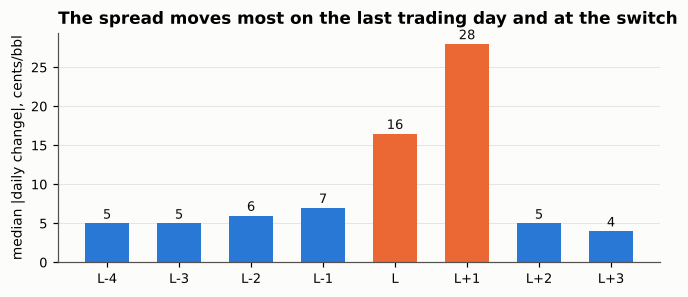

L-4   0.050
L-3   0.050
L-2   0.060
L-1   0.070
L     0.160
L+1   0.280
L+2   0.050
L+3   0.040


In [4]:
Da = EX["D_all"]; usd_all = (Da.CL2 - Da.CL1).diff().abs()
Sa = Da.index
rows = {k: [] for k in range(-4, 4)}
for L in EX["E"]:
    if pd.Timestamp(FIRST_FRI) < L <= pd.Timestamp(LAST_FRI):
        i = Sa.get_loc(L)
        for k in rows:
            if 0 < i + k < len(Sa):
                rows[k].append(usd_all.iloc[i + k])
around = pd.Series({("L%+d" % k if k else "L"): np.median(v) for k, v in rows.items()})
fig, ax = plt.subplots(figsize=(6.2, 2.8))
ax.bar(around.index, 100 * around.values, color=[C["orange"] if k in ("L", "L+1") else C["blue"] for k in around.index], width=0.6)
for i, v in enumerate(around.values):
    ax.text(i, 100 * v + 0.6, f"{100*v:.0f}", ha="center", fontsize=8.5, color=C["ink"])
ax.set_title("The spread moves most on the last trading day and at the switch")
ax.set_ylabel("median |daily change|, cents/bbl"); ax.grid(axis="x", visible=False)
savefig("01_expiry_calendar_check")
print(around.round(2).to_string())

### 1.3 The roll artefact: December 2008
The clearest example of why the raw series misleads. In the last days of the January 2009 contract CL1 fell much more than CL2, so the raw
carry jumped and then dropped back at the switch. A position rolled before expiry earned almost none of that move.


Date   2008-12-16  2008-12-17  2008-12-18  2008-12-19  2008-12-22
CL1        43.600      40.060      36.220      33.870      39.910
CL2        46.700      44.610      41.670      42.360      42.880
carry       7.110      11.360      15.050      25.070       7.440


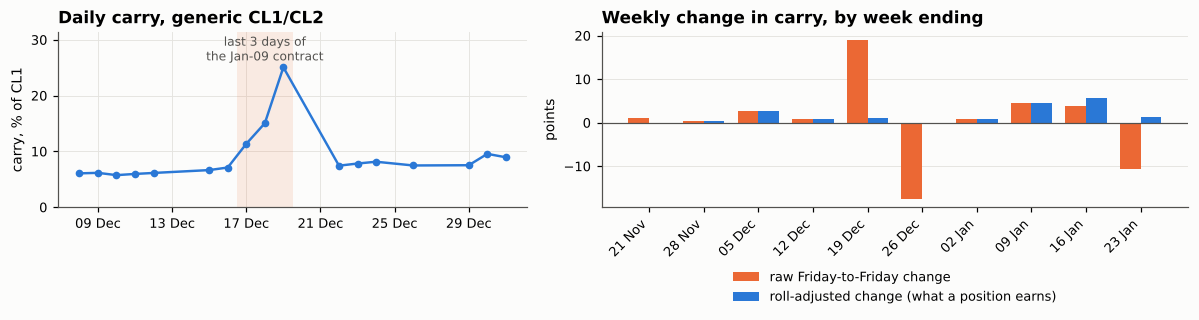

In [5]:
d = EX["D_all"].loc["2008-12-08":"2008-12-31"].copy()
d["carry"] = 100 * (d.CL2 / d.CL1 - 1)
print(d.loc["2008-12-16":"2008-12-22"].round(2).T.to_string())

wk = Z.loc["2008-11-14":"2009-01-16", ["target_friday", "y_raw", "y"]].set_index("target_friday")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
ax.plot(d.index, d.carry, color=C["blue"], marker="o", ms=4)
ax.axvspan(pd.Timestamp("2008-12-16 12:00"), pd.Timestamp("2008-12-19 12:00"), color=C["orange"], alpha=0.12, lw=0)
ax.text(pd.Timestamp("2008-12-18"), d.carry.max() * 1.02, "last 3 days of\nthe Jan-09 contract", ha="center", va="bottom", fontsize=8, color=C["mute"])
ax.set_ylim(0, d.carry.max() * 1.25)
ax.set_title("Daily carry, generic CL1/CL2"); ax.set_ylabel("carry, % of CL1")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b")); ax.xaxis.set_major_locator(mdates.DayLocator(interval=4))
ax = axes[1]
xx = np.arange(len(wk)); w = 0.38
ax.bar(xx - w / 2, wk.y_raw, w, color=C["orange"], label="raw Friday-to-Friday change")
ax.bar(xx + w / 2, wk.y, w, color=C["blue"], label="roll-adjusted change (what a position earns)")
ax.set_xticks(xx); ax.set_xticklabels([t.strftime("%d %b") for t in wk.index], rotation=45, ha="right")
ax.axhline(0, color=C["mute"], lw=0.8); ax.grid(axis="x", visible=False)
ax.set_title("Weekly change in carry, by week ending"); ax.set_ylabel("points"); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.30), ncol=1)
savefig("02_roll_artefact_dec2008")

### 1.4 Know your data: the series, the roll flags and the outliers
Outliers are flagged with the training mean and standard deviation (|z| > 4) and kept. We do not delete them: they are real weeks that a
trader had to live through.


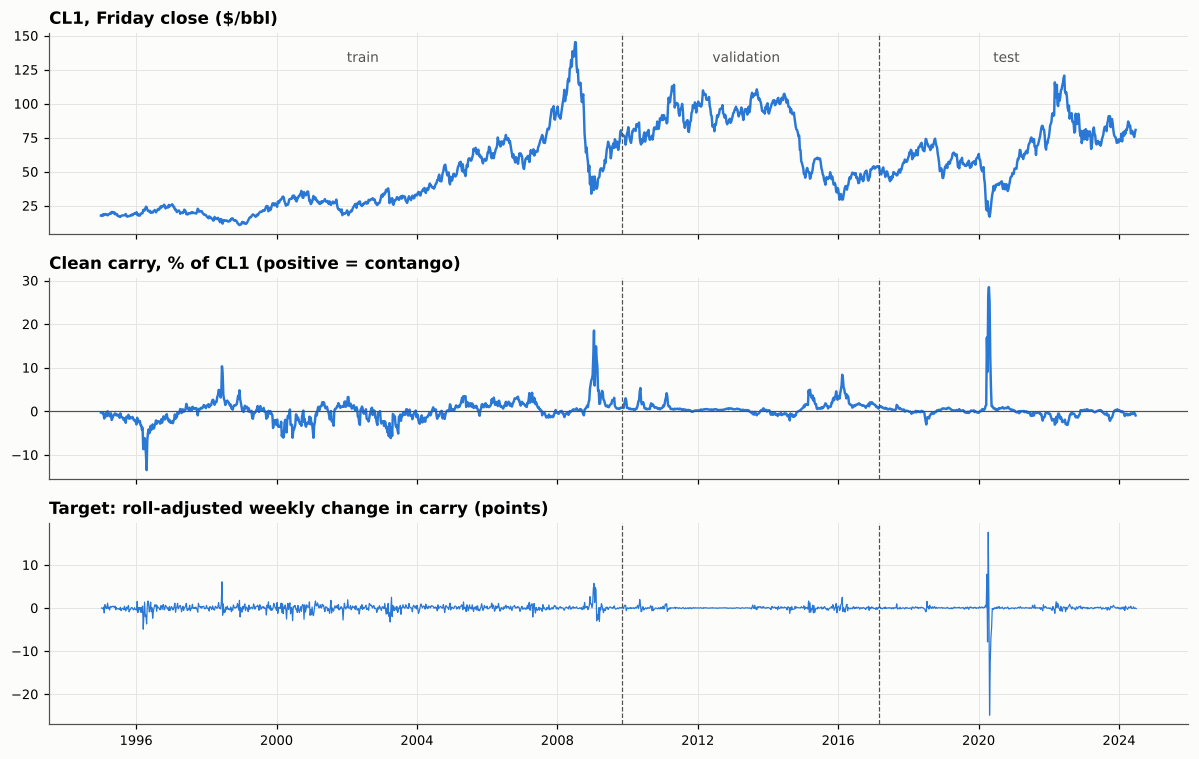

             share of weeks, %  mean kept days  sd of y (train)
roll week               23.000           2.050            0.510
window week             17.480           3.140            0.920
clean week              59.520           4.810            0.850

training outliers |z| > 4: 8 weeks, 5 inside a named event window
           target_friday      y    CL1      z  in a named event window
friday                                                                
1996-03-08    1996-03-15 -4.910 19.610 -6.110                    False
1996-04-12    1996-04-19 -3.700 24.290 -4.610                    False
1998-06-05    1998-06-12  6.080 15.070  7.480                     True
2003-03-21    2003-03-28 -3.260 26.910 -4.060                    False
2009-01-02    2009-01-09  4.480 46.340  5.500                     True
2009-01-09    2009-01-16  5.700 40.830  7.010                     True
2009-01-23    2009-01-30  4.780 46.470  5.870                     True
2009-01-30    2009-02-06  4.210 41.680

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
axes[0].plot(Z.index, Z.CL1, color=C["blue"]); axes[0].set_title("CL1, Friday close ($/bbl)")
axes[1].plot(Z.index, Z.carry_clean, color=C["blue"]); axes[1].axhline(0, color=C["mute"], lw=0.8)
axes[1].set_title("Clean carry, % of CL1 (positive = contango)")
axes[2].plot(Z.target_friday, Z.y, color=C["blue"], lw=0.8); axes[2].set_title("Target: roll-adjusted weekly change in carry (points)")
for ax in axes:
    for dte in (TRAIN_END, VAL_END):
        ax.axvline(pd.Timestamp(dte), color=C["mute"], lw=0.8, ls="--")
axes[0].text(pd.Timestamp("2002-01-01"), Z.CL1.max() * 0.9, "train", color=C["mute"], fontsize=9)
axes[0].text(pd.Timestamp("2012-06-01"), Z.CL1.max() * 0.9, "validation", color=C["mute"], fontsize=9)
axes[0].text(pd.Timestamp("2020-06-01"), Z.CL1.max() * 0.9, "test", color=C["mute"], fontsize=9)
savefig("03_series_overview")

flags = pd.DataFrame({
    "share of weeks, %": [100 * (Z.roll_week).mean(), 100 * Z.window_week.mean(), 100 * (~Z.roll_week & ~Z.window_week).mean()],
    "mean kept days": [Z.n_kept[Z.roll_week].mean(), Z.n_kept[Z.window_week].mean(), Z.n_kept[~Z.roll_week & ~Z.window_week].mean()],
    "sd of y (train)": [Z.y[Z.roll_week & (Z.split == "train")].std(), Z.y[Z.window_week & (Z.split == "train")].std(),
                        Z.y[~Z.roll_week & ~Z.window_week & (Z.split == "train")].std()]},
    index=["roll week", "window week", "clean week"])
print(flags.round(2).to_string())

# outliers flagged with TRAINING moments (|z| > 4): flagged, not removed
mu, sd = DF.y[TR].mean(), DF.y[TR].std()
zs = (DF.y - mu) / sd
out = DF.loc[(zs.abs() > 4) & TR, ["target_friday", "y", "CL1"]].assign(z=zs)
ev_any = DF[["ev_1998", "ev_2008", "ev_2020"]].sum(axis=1) > 0
out["in a named event window"] = ev_any[out.index]
print(f"\ntraining outliers |z| > 4: {len(out)} weeks, {int(out['in a named event window'].sum())} inside a named event window")
print(out.round({"y": 2, "CL1": 2, "z": 2}).to_string())

**Section 1 summary** (printed from the data)

In [7]:
print(f"- Build accepted: 14/14 reference values reproduce; {CSV} has {Z.shape[0]} rows x {Z.shape[1]} columns.")
print(f"- Common estimation sample starts {COMMON_START.date()}: train {int(TR.sum())}, validation {int(VA.sum())}, test {int(TE.sum())}.")
print(f"- Raw weekly change in carry has sd {Z.y_raw.std():.2f} points; the roll-adjusted change {Z.y.std():.2f}. The gap is the roll.")
print(f"- Median |daily $ spread change|: {100*around['L']:.0f} cents on L and {100*around['L+1']:.0f} at the switch, against about {100*around['L-3']:.0f} on a normal day.")

- Build accepted: 14/14 reference values reproduce; weekly_dataset.csv has 1539 rows x 35 columns.
- Common estimation sample starts 1995-03-03: train 765, validation 382, test 383.
- Raw weekly change in carry has sd 1.47 points; the roll-adjusted change 1.10. The gap is the roll.
- Median |daily $ spread change|: 16 cents on L and 28 at the switch, against about 5 on a normal day.


## 2. Stationarity and knowing the data (training sample only)

Helpers first. All regressions use OLS with Newey–West standard errors (7 lags). Weekly oil data has changing volatility and some
autocorrelation, and both make ordinary standard errors unreliable.


In [8]:
def ols(d, ycol, xcols, hac=NW):
    """OLS with a constant and Newey-West standard errors (hac=None -> classical)."""
    Xd = sm.add_constant(d[list(xcols)].astype(float), has_constant="add")
    m = sm.OLS(d[ycol].astype(float), Xd)
    return m.fit(cov_type="HAC", cov_kwds={"maxlags": hac}) if hac else m.fit()


def half_life(psi, t):
    """Only defined for -1 < psi < 0; only quoted if the t-stat is below -2.86 (the Dickey-Fuller 5% value, used as a
    conservative bar for every row)."""
    if -1 < psi < 0 and t < -2.86:
        return f"{np.log(0.5) / np.log(1 + psi):.1f} weeks"
    if -1 < psi < 0:
        return f"not quoted (t > -2.86; arithmetic gives {np.log(0.5) / np.log(1 + psi):.1f})"
    return "none (psi >= 0)"


def unit_root_row(s, reg="c"):
    s = pd.Series(s).dropna().astype(float)
    a = adfuller(s, maxlag=12, regression=reg, autolag="BIC")
    k = kpss(s, regression=reg, nlags="auto")
    pp = PhillipsPerron(s, trend=reg)                 # Newey-West long-run variance, default bandwidth
    adf_rej, kpss_rej = a[0] < a[4]["5%"], k[0] > k[3]["5%"]
    verdict = {(True, False): "stationary", (False, True): "unit root", (True, True): "conflict (near unit root or break)",
               (False, False): "grey area (low power)"}[(adf_rej, kpss_rej)]
    return {"form": {"c": "constant", "ct": "constant + trend"}[reg], "ADF": a[0], "ADF 5% cv": a[4]["5%"], "ADF lags": a[2],
            "PP": pp.stat, "PP 5% cv": pp.critical_values["5%"], "KPSS": k[0], "KPSS 5% cv": k[3]["5%"], "reading": verdict}


T = DF[TR]                                     # training rows of the common sample
print("training rows:", len(T), "| targets", T.target_friday.min().date(), "to", T.target_friday.max().date())

training rows: 765 | targets 1995-03-10 to 2009-10-30


### 2.1 Unit-root tests (ADF with BIC lags, max 12; Phillips–Perron; KPSS)
ADF: H₀ = unit root, reject below the critical value. KPSS: H₀ = stationary, reject above it. Phillips–Perron has the same H₀ as ADF but corrects for autocorrelation and changing variance with Newey–West errors instead of lags,
which suits this data. ADF has little power when a series is stationary but close to a unit root, so we read ADF and KPSS together
(the `reading` column) and use Phillips–Perron as a check on ADF. A regression on a non-stationary level can look significant
for no reason (spurious regression), which is why we need to know this before modelling.


In [9]:
ur = {
    "log CL1 (level)": unit_root_row(np.log(T.CL1), "ct"),
    "log CL2 (level)": unit_root_row(np.log(T.CL2), "ct"),
    "Δ log CL1": unit_root_row(np.log(T.CL1).diff(), "c"),
    "carry_raw (level; contains roll resets, descriptive only)": unit_root_row(T.carry_raw, "c"),
    "carry_clean (level; descriptive only)": unit_root_row(T.carry_clean, "c"),
    "y (target: roll-adjusted Δcarry)": unit_root_row(T.y, "c"),
}
for c in ["stock_chg", "stock_surprise", "stock_surprise_4w", "prod_chg_4w", "rig_chg_4w_pct", "comm_net", "cl1_mom4",
          "crack_chg", "VIX", "DXY_ret", "y3m_chg"]:
    ur[c] = unit_root_row(T[c], "c")
# 3M yield level, monthly, re-dated, training window
y3 = EX["y3m_level"]; y3 = y3[(y3.index >= "1995-01-01") & (y3.index <= TRAIN_END)]
ur["3M yield level (monthly)"] = unit_root_row(y3, "c")
ur["3M yield change (monthly)"] = unit_root_row(y3.diff(), "c")
UR = save_table(pd.DataFrame(ur).T, "t2_unit_roots")
PP_AGREES = ((UR.ADF < UR["ADF 5% cv"]) == (UR.PP < UR["PP 5% cv"]))
print(UR.to_string(float_format=lambda v: f"{v:.2f}"))
print("\nNote: monthly series are forward-filled to weekly rows, which makes weekly-row tests on VIX, DXY_ret, crack_chg and y3m_chg")
print("look more persistent than the monthly data is. The 3M yield rows above use the monthly values directly.")
print("Phillips-Perron agrees with ADF on every row." if PP_AGREES.all() else f"Phillips-Perron disagrees with ADF on: {list(UR.index[~PP_AGREES])}")

# Zivot-Andrews on the raw Friday level (endogenous break; descriptive only)
za = zivot_andrews(T.carry_raw.values, regression="c", maxlag=12, autolag="BIC")
print(f"\nZivot-Andrews, raw carry level: stat {za[0]:.2f} (5% cv {za[2]['5%']:.2f}), break at target week {T.target_friday.iloc[za[4]].date()}")

                                                                       form    ADF ADF 5% cv ADF lags     PP PP 5% cv KPSS KPSS 5% cv                             reading
log CL1 (level)                                            constant + trend  -2.88     -3.42        0  -3.09    -3.42 0.31       0.15                           unit root
log CL2 (level)                                            constant + trend  -2.70     -3.42        0  -2.97    -3.42 0.34       0.15                           unit root
Δ log CL1                                                          constant -29.97     -2.87        0 -29.87    -2.87 0.05       0.46                          stationary
carry_raw (level; contains roll resets, descriptive only)          constant  -4.77     -2.87        4 -10.11    -2.87 0.84       0.46  conflict (near unit root or break)
carry_clean (level; descriptive only)                              constant  -4.46     -2.87        2  -6.44    -2.87 0.91       0.46  conflict (near 



Note: monthly series are forward-filled to weekly rows, which makes weekly-row tests on VIX, DXY_ret, crack_chg and y3m_chg
look more persistent than the monthly data is. The 3M yield rows above use the monthly values directly.
Phillips-Perron agrees with ADF on every row.



Zivot-Andrews, raw carry level: stat -5.74 (5% cv -4.81), break at target week 1999-08-27


### 2.2 Dickey–Fuller on the spread: the generic series against the spread a position holds

Two Dickey–Fuller tests and one predictive regression. Each answers a different question.

1. **Dickey–Fuller on the generic carry.** Δcarry on last week's carry level, raw Friday closes. H₀ = unit root; reject if the statistic is below **−2.86**.
   This is what a chart of CL2/CL1 shows, roll jumps included.
2. **Dickey–Fuller on the cumulative P&L of holding the spread.** The level is rebuilt by adding up the roll-adjusted weekly changes *y*, so it is the path of a position
   that is rolled each month. Same test, same −2.86. This is the test that matters for trading.
3. **Predictive regression.** Does today's clean carry forecast next week's earnable change?

$$y_{t+1} = \alpha + \psi\,\text{carry}^{clean}_t + \sum_i \gamma_i\,y_{t-i+1} + u_{t+1}$$

   ψ < 0 would mean a wide contango tends to narrow. Here *y* is not the change of `carry_clean` (the clean level still resets at each roll and *y* does not),
   so this is **not** strictly a Dickey–Fuller regression. It has the same problem, though: carry is very persistent (weekly AR(1) about 0.9) and its
   shocks move with the target (correlation about 0.67 in training), which pushes an ordinary t-statistic towards "finding" mean reversion.
   So a negative ψ counts as evidence only if its Newey–West t-statistic is below **−2.86**. In training ψ is positive, so the choice changes nothing there;
   it matters for the post-test check in Section 9.0.

The table of ψ is shown first on 1995–2004 (the training window of an earlier version, kept as a check on the build), then on the full training window.


In [10]:
X_fk, _ = build_weekly(drop_frozen=False, check=False, verbose=False)       # frozen sessions kept, for the comparison rows only


def psi_row(frame, ycol, lev, mask):
    d = frame.loc[mask, [ycol, lev]].dropna()
    r = ols(d, ycol, [lev])
    return {"psi": r.params[lev], "t": r.tvalues[lev], "half-life": half_life(r.params[lev], r.tvalues[lev]), "n": int(r.nobs)}


def table_01(end):
    m = lambda f: (f.target_friday <= end)
    return pd.DataFrame({
        "raw change on raw level": psi_row(X, "y_raw", "carry_raw", m(X)),
        "adjusted, frozen days kept, raw level": psi_row(X_fk, "y", "carry_raw", m(X_fk)),
        "adjusted, frozen days kept, clean level": psi_row(X_fk, "y", "carry_clean", m(X_fk)),
        "ADJUSTED, FROZEN DROPPED, CLEAN LEVEL (the rule)": psi_row(X, "y", "carry_clean", m(X)),
        "adjusted $ change on $ clean level": psi_row(X, "y_usd", "usd_clean", m(X)),
    }).T


t01_0 = table_01("2004-12-31"); t01_1 = table_01(TRAIN_END)
print("1995-2004 (reference values: -0.17/-4.34, -0.05/-1.07, -0.06/-1.06, +0.03/1.34, +0.03/1.36)")
print(t01_0.to_string(float_format=lambda v: f"{v:.2f}"))
print("\nFull training window, targets to 30 Oct 2009 (the numbers to quote)")
print(t01_1.to_string(float_format=lambda v: f"{v:.2f}"))
r0 = t01_0.loc["ADJUSTED, FROZEN DROPPED, CLEAN LEVEL (the rule)"]
assert abs(r0.psi - 0.03) < 0.006 and abs(r0.t - 1.34) < 0.03, "reference headline not reproduced"
save_table(pd.concat({"1995-2004": t01_0, "full training": t01_1}), "t2_psi_raw_vs_adjusted")

# DF form with lags of y chosen by BIC (max 12), common sample, same rows for every p
L12 = pd.concat({f"yl{i}": X["y"].shift(i) for i in range(1, 13)}, axis=1).loc[DF.index]
d12 = pd.concat([T[["y", "carry_clean"]], L12[TR]], axis=1).dropna()
bic = {p: ols(d12, "y", ["carry_clean"] + [f"yl{i}" for i in range(1, p + 1)]).bic for p in range(13)}
p_df = min(bic, key=bic.get)
r_df = ols(d12, "y", ["carry_clean"] + [f"yl{i}" for i in range(1, p_df + 1)])
PSI_TRAIN, PSI_T = r_df.params["carry_clean"], r_df.tvalues["carry_clean"]
PSI_SIG = (PSI_T < -2.86) or (PSI_T > 1.96)                                # Section 2.2: -2.86 for a pull-back
print(f"\n3. Predictive regression, lags of y by BIC (max 12): p = {p_df}, psi = {PSI_TRAIN:+.3f}, HAC t = {PSI_T:.2f} (bar: below -2.86 for a pull-back, above 1.96 for a push-out) ->",
      ("clean carry forecasts the earnable change, " + ("narrowing (mean reversion)" if PSI_TRAIN < 0 else "widening (no mean reversion)")) if PSI_SIG
      else "clean carry does not forecast the earnable change")

# 1 and 2: true Dickey-Fuller tests (ADF with BIC lags, max 12, constant), full training window
tr_all = X[X.target_friday <= TRAIN_END]
held = tr_all.carry_clean.iloc[0] + tr_all.y.cumsum().shift(1).fillna(0.0)      # level at Friday t of a spread that is held and rolled


def df_test(s):
    a = adfuller(pd.Series(s).dropna().astype(float), maxlag=12, regression="c", autolag="BIC")
    return {"DF statistic": a[0], "5% critical value": a[4]["5%"], "lags": a[2],
            "reading": "unit root rejected: looks mean-reverting" if a[0] < a[4]["5%"] else "unit root not rejected: behaves like a random walk"}


DFT = save_table(pd.DataFrame({"1. generic carry (raw Friday level)": df_test(tr_all.carry_raw),
                               "2. cumulative P&L of holding the spread (roll-adjusted changes added up)": df_test(held)}).T, "t2_dickey_fuller")
DF_RAW, DF_HELD = DFT.iloc[0], DFT.iloc[1]
print("\nDickey-Fuller tests, full training window (reject the unit root below -2.86)")
print(DFT.to_string(float_format=lambda v: f"{v:.2f}"))

1995-2004 (reference values: -0.17/-4.34, -0.05/-1.07, -0.06/-1.06, +0.03/1.34, +0.03/1.36)
                                                   psi     t                                      half-life    n
raw change on raw level                          -0.17 -4.34                                      3.8 weeks  522
adjusted, frozen days kept, raw level            -0.05 -1.07  not quoted (t > -2.86; arithmetic gives 12.5)  522
adjusted, frozen days kept, clean level          -0.06 -1.06  not quoted (t > -2.86; arithmetic gives 11.9)  522
ADJUSTED, FROZEN DROPPED, CLEAN LEVEL (the rule)  0.03  1.34                                none (psi >= 0)  522
adjusted $ change on $ clean level                0.03  1.33                                none (psi >= 0)  522

Full training window, targets to 30 Oct 2009 (the numbers to quote)
                                                   psi     t                                       half-life    n
raw change on raw level                        

### 2.3 Is any mean reversion real? Checks on the full training window
If mean reversion were real it should survive small changes to the regression: trimming outliers, skipping a week, dropping crisis periods,
splitting the sample. The checks were chosen before looking at the results.


In [11]:
WIDE = T.carry_clean.quantile(0.90)                        # training 90th percentile
d = T.copy()
lo, hi = d.y.quantile([0.01, 0.99]); d["y_w"] = d.y.clip(lo, hi)
d["carry_clean_lag1"] = DF.carry_clean.shift(1)[TR]
chk = {}
def add(name, frame, ycol, xcols, key="carry_clean"):
    r = ols(frame.dropna(subset=[ycol] + xcols), ycol, xcols)
    chk[name] = {"psi": r.params[key], "t": r.tvalues[key], "n": int(r.nobs)}
add("baseline (clean level, adjusted target)", d, "y", ["carry_clean"])
add("raw target on raw level (roll artefact)", d, "y_raw", ["carry_raw"], "carry_raw")
add("target winsorised at 1% / 99%", d, "y_w", ["carry_clean"])
add("level skipped one week", d, "y", ["carry_clean_lag1"], "carry_clean_lag1")
add("adding one lag of y", d, "y", ["carry_clean", "y_lag1"])
add("excluding 1998", d[d.target_friday.dt.year != 1998], "y", ["carry_clean"])
add("excluding ev_1998 and ev_2008 windows", d[(d.ev_1998 == 0) & (d.ev_2008 == 0)], "y", ["carry_clean"])
add("targets 1995-1999", d[d.target_friday < "2000-01-01"], "y", ["carry_clean"])
add("targets 2000-2004", d[(d.target_friday >= "2000-01-01") & (d.target_friday < "2005-01-01")], "y", ["carry_clean"])
add("targets 2005-Oct 2009", d[d.target_friday >= "2005-01-01"], "y", ["carry_clean"])
add(f"wide contango only (clean carry > {WIDE:.2f})", d[d.carry_clean > WIDE], "y", ["carry_clean"])
CHK = save_table(pd.DataFrame(chk).T, "t2_mean_reversion_checks")
print(CHK.to_string(float_format=lambda v: f"{v:.2f}"))
print(f"\ntraining 90th percentile of clean carry = {WIDE:.2f}")

                                          psi     t      n
baseline (clean level, adjusted target)  0.04  1.32 765.00
raw target on raw level (roll artefact) -0.18 -4.83 765.00
target winsorised at 1% / 99%            0.01  0.55 765.00
level skipped one week                   0.04  1.43 764.00
adding one lag of y                      0.03  1.13 765.00
excluding 1998                           0.04  1.28 713.00
excluding ev_1998 and ev_2008 windows    0.02  0.90 700.00
targets 1995-1999                        0.04  1.17 252.00
targets 2000-2004                        0.02  0.86 261.00
targets 2005-Oct 2009                    0.06  0.81 252.00
wide contango only (clean carry > 2.23)  0.07  0.69  77.00

training 90th percentile of clean carry = 2.23


### 2.4 Is there anything to forecast? ACF, PACF, Ljung–Box
Ljung–Box and the ACF bands assume constant variance, which this series does not have (Section 2.5). So the same question is asked again with a regression of *y* on its own four lags, once with classical and once with heteroskedasticity-robust (White) errors.

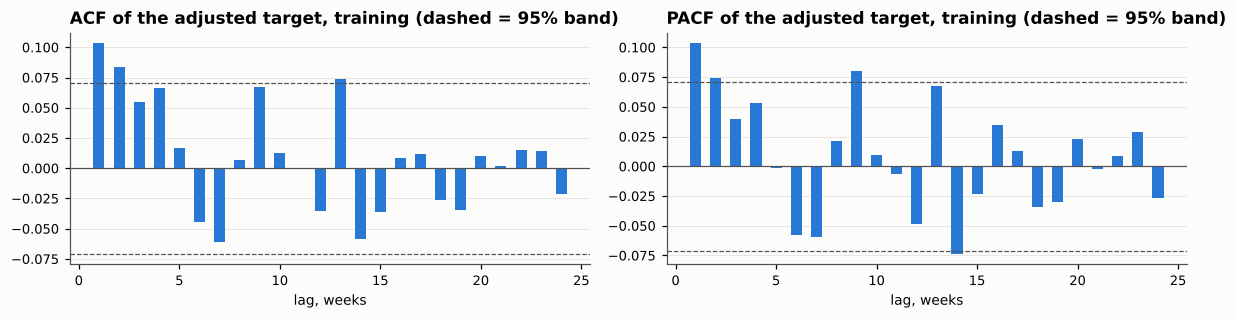

Ljung-Box on y (H0: no autocorrelation up to the lag)
        Q     p
4  19.289 0.001
12 28.455 0.005
24 38.771 0.029
First-order autocorrelation: raw carry level 0.82, y 0.10
y on its own 4 lags, joint test that all are zero: classical p = 0.003, robust (White) p = 0.735
-> the apparent autocorrelation is produced by a few very volatile weeks; with robust errors there is nothing to forecast from past changes.


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
band = 1.96 / np.sqrt(len(T))
for ax, vals, name in [(axes[0], acf(T.y, nlags=24)[1:], "ACF"), (axes[1], pacf(T.y, nlags=24)[1:], "PACF")]:
    ax.bar(range(1, 25), vals, color=C["blue"], width=0.55)
    ax.axhline(band, color=C["mute"], ls="--", lw=0.8); ax.axhline(-band, color=C["mute"], ls="--", lw=0.8); ax.axhline(0, color=C["mute"], lw=0.8)
    ax.set_title(f"{name} of the adjusted target, training (dashed = 95% band)"); ax.set_xlabel("lag, weeks"); ax.grid(axis="x", visible=False)
savefig("04_acf_pacf_target")
LB = acorr_ljungbox(T.y, lags=[4, 12, 24]).rename(columns={"lb_stat": "Q", "lb_pvalue": "p"})
print("Ljung-Box on y (H0: no autocorrelation up to the lag)"); print(LB.to_string(float_format=lambda v: f"{v:.3f}"))
print("First-order autocorrelation: raw carry level %.2f, y %.2f" % (T.carry_raw.autocorr(1), T.y.autocorr(1)))
lagc = [f"y_lag{i}" for i in range(1, 5)]
LAG_P = {}
for lab, cov in [("classical", "nonrobust"), ("robust (White)", "HC1")]:
    rl = sm.OLS(T.y, sm.add_constant(T[lagc].astype(float))).fit(cov_type=cov)
    LAG_P[lab] = float(rl.f_test(np.eye(5)[1:]).pvalue)
print("y on its own 4 lags, joint test that all are zero: " + ", ".join(f"{k} p = {v:.3f}" for k, v in LAG_P.items()))
print("->", "the autocorrelation survives robust errors." if LAG_P["robust (White)"] < 0.05 else
      "the apparent autocorrelation is produced by a few very volatile weeks; with robust errors there is nothing to forecast from past changes.")

### 2.5 Seasonality and volatility regimes
Month dummies test for seasonality in the target. ARCH-LM and Goldfeld–Quandt test whether its volatility is constant, which decides
whether ordinary standard errors can be trusted.


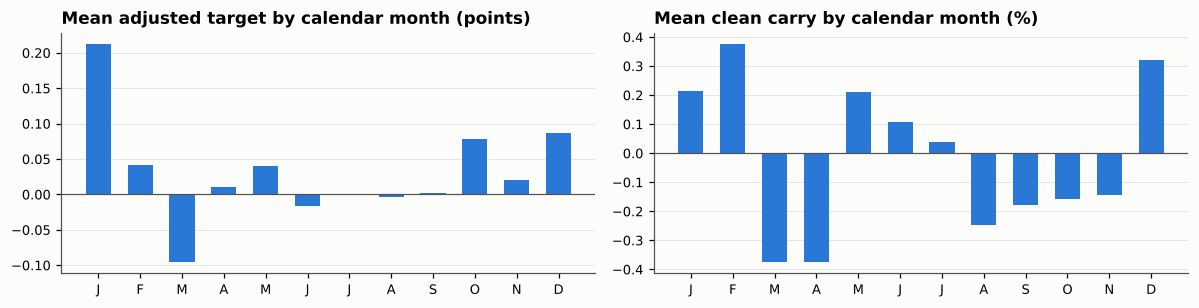

11 month dummies, joint F-test (HAC): F = 0.32, p = 0.981 -> not needed
ARCH-LM (4 lags) on y: LM = 108.5, p = 0.0000
Goldfeld-Quandt, split at Jan 2005: variance ratio late/early = 1.12, p = 0.3050 (sd 0.79 -> 0.84)


In [13]:
d = T.copy(); d["month"] = d.target_friday.dt.month
bym = d.groupby("month")[["y", "carry_clean"]].mean()
fig, axes = plt.subplots(1, 2, figsize=(11, 2.9))
for ax, col, ttl in [(axes[0], "y", "Mean adjusted target by calendar month (points)"), (axes[1], "carry_clean", "Mean clean carry by calendar month (%)")]:
    ax.bar(bym.index, bym[col], color=C["blue"], width=0.6); ax.axhline(0, color=C["mute"], lw=0.8)
    ax.set_xticks(range(1, 13)); ax.set_xticklabels(list("JFMAMJJASOND")); ax.set_title(ttl); ax.grid(axis="x", visible=False)
savefig("05_seasonality")
md = pd.get_dummies(d.month, prefix="m", drop_first=True).astype(float)
MONTHS = list(md.columns)
dm = pd.concat([d[["y"]], md], axis=1)
rm = ols(dm, "y", MONTHS)
ft = rm.f_test(np.eye(len(rm.params))[1:])
SEAS_P = float(ft.pvalue)
print(f"11 month dummies, joint F-test (HAC): F = {float(ft.fvalue):.2f}, p = {SEAS_P:.3f} ->", "keep" if SEAS_P < 0.05 else "not needed")

yc = T.y - T.y.mean()
arch = het_arch(yc, nlags=4)
early, late = T.y[T.target_friday < "2005-01-07"], T.y[T.target_friday >= "2005-01-07"]
gq = late.var() / early.var(); gq_p = 2 * min(st.f.cdf(gq, len(late) - 1, len(early) - 1), st.f.sf(gq, len(late) - 1, len(early) - 1))
print(f"ARCH-LM (4 lags) on y: LM = {arch[0]:.1f}, p = {arch[1]:.4f}")
print(f"Goldfeld-Quandt, split at Jan 2005: variance ratio late/early = {gq:.2f}, p = {gq_p:.4f} (sd {early.std():.2f} -> {late.std():.2f})")

**Section 2 summary** (printed from the data)

In [14]:
r1 = t01_1.loc["ADJUSTED, FROZEN DROPPED, CLEAN LEVEL (the rule)"]; rr = t01_1.loc["raw change on raw level"]
print(f"- Price levels: log CL1 is '{UR.loc['log CL1 (level)', 'reading']}', so we do not model levels. The target y is '{UR.loc['y (target: roll-adjusted Δcarry)', 'reading']}'.")
print(f"- Roll artefact, full training: raw psi = {rr.psi:+.2f} (t {rr.t:.2f}); roll-adjusted psi = {r1.psi:+.2f} (t {r1.t:.2f}).")
print(f"- Dickey-Fuller, generic carry: {DF_RAW['DF statistic']:.2f} against {DF_RAW['5% critical value']:.2f} -> {DF_RAW['reading']}.")
print(f"- Dickey-Fuller, cumulative P&L of holding the spread: {DF_HELD['DF statistic']:.2f} against {DF_HELD['5% critical value']:.2f} -> {DF_HELD['reading']}.")
print(f"- Predictive regression (BIC p = {p_df}): psi = {PSI_TRAIN:+.3f}, HAC t = {PSI_T:.2f}: " +
      ("clean carry forecasts the earnable change." if PSI_SIG else "clean carry does not forecast the earnable change; no half-life is quoted."))
print(f"- Ljung-Box p-values at 4/12/24 lags: {LB.p.iloc[0]:.3f} / {LB.p.iloc[1]:.3f} / {LB.p.iloc[2]:.3f}; "
      f"4 lags of y with robust errors: p = {LAG_P['robust (White)']:.3f}. Month dummies: p = {SEAS_P:.3f}.")
print(f"- Volatility is not constant (ARCH-LM p = {arch[1]:.4f}; Goldfeld-Quandt p = {gq_p:.4f}): Newey-West errors throughout, rolling window as robustness.")

- Price levels: log CL1 is 'unit root', so we do not model levels. The target y is 'stationary'.
- Roll artefact, full training: raw psi = -0.18 (t -4.84); roll-adjusted psi = +0.04 (t 1.32).
- Dickey-Fuller, generic carry: -4.80 against -2.87 -> unit root rejected: looks mean-reverting.
- Dickey-Fuller, cumulative P&L of holding the spread: 0.01 against -2.87 -> unit root not rejected: behaves like a random walk.
- Predictive regression (BIC p = 0): psi = +0.041, HAC t = 1.33: clean carry does not forecast the earnable change; no half-life is quoted.
- Ljung-Box p-values at 4/12/24 lags: 0.001 / 0.005 / 0.029; 4 lags of y with robust errors: p = 0.735. Month dummies: p = 0.981.
- Volatility is not constant (ARCH-LM p = 0.0000; Goldfeld-Quandt p = 0.3050): Newey-West errors throughout, rolling window as robustness.


## 3. Predictors

We wrote down the predictors and the sign we expected before estimating anything. That way a coefficient is judged against the theory,
and a wrong sign cannot be explained away afterwards.

| Predictor | Expected sign | Story |
| --- | --- | --- |
| `carry_clean` | − | Storage arbitrage pulls a wide contango back |
| `stock_surprise` / `stock_surprise_4w` | + | A bigger-than-normal build makes the prompt barrel less scarce |
| `prod_chg_4w` | + | More supply loosens the prompt market |
| `roll_week`, `window_week`, `roll_x_carry` | ? | Controls: in roll weeks the target is mostly the new pair |

**Why these.** The spread is the price of storing oil, so the theory points to how full the tanks are and how much oil is coming.
The stock surprise is the weekly stock change minus the average change in the same week of the previous five years, so a normal seasonal
build does not count as news. We kept the theory set small on purpose: every extra predictor is another chance to fit noise.

**What we left out, and why.** Monthly production, inventories, rigs and positioning duplicate the weekly series, which are more timely.
CPI and industrial production are published about two weeks after the month they describe, so their month-end dates would be look-ahead.
The 10-year yield is left out because the 3-month yield is the rate that finances a stored barrel. Monthly Brent tracks CL1 closely, so it
says little about the shape of the WTI curve. Total open interest measures the size of the market, not how full the tanks are. Oil-company
shares, the S&P 500, gasoline prices and dry-bulk freight have no direct link to the cost of storing crude. Daily Brent, crack and freight are dropped because
their dates do not line up with CL1 and CL2 (in July 2008 the daily Brent column sits near $50 while CL1 is above $135); the monthly crack
spread is used instead.

**The Lasso pool** has 18 candidates: the 7 columns above (both surprise versions, three roll controls) plus 11 others
(four lags of *y*, CL1 momentum, commercial net position, rig count change, crack spread change, VIX, dollar return, 3M yield change).


18 Lasso candidates


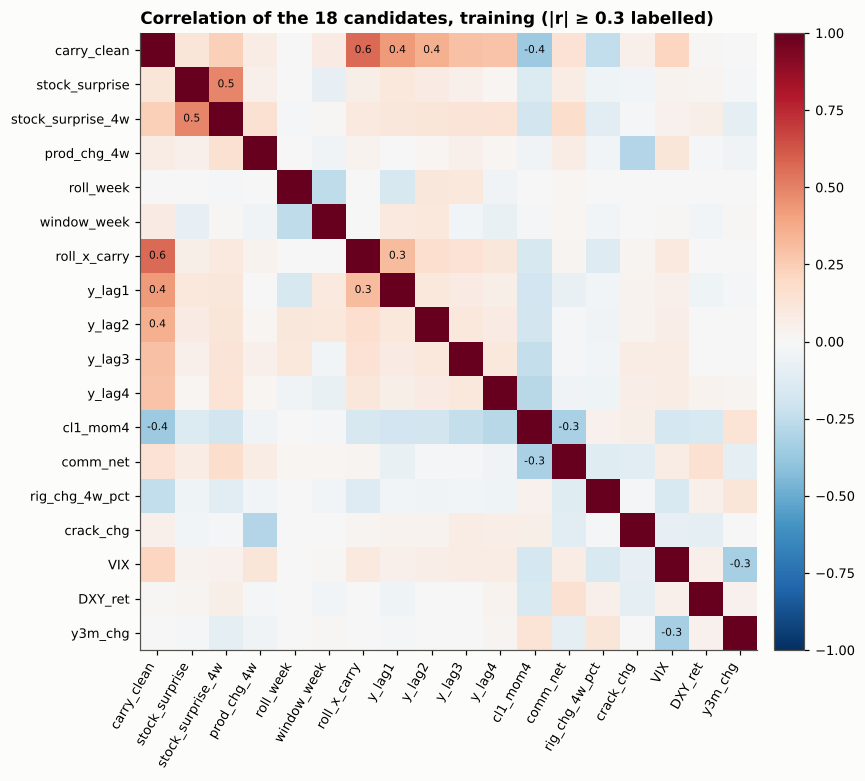


VIF, M1 set with stock_surprise:
carry_clean      1.510
stock_surprise   1.030
prod_chg_4w      1.010
roll_week        1.070
window_week      1.090
roll_x_carry     1.480

VIF, M1 set with stock_surprise_4w:
carry_clean         1.570
stock_surprise_4w   1.090
prod_chg_4w         1.030
roll_week           1.070
window_week         1.080
roll_x_carry        1.480


In [15]:
SURPRISES = ["stock_surprise", "stock_surprise_4w"]
CONTROLS = ["roll_week", "window_week", "roll_x_carry"]
POOL = (["carry_clean"] + SURPRISES + ["prod_chg_4w"] + CONTROLS + [f"y_lag{i}" for i in range(1, 5)] +
        ["cl1_mom4", "comm_net", "rig_chg_4w_pct", "crack_chg", "VIX", "DXY_ret", "y3m_chg"])
EXPECTED = {"carry_clean": -1, "stock_surprise": +1, "stock_surprise_4w": +1, "prod_chg_4w": +1}
print(len(POOL), "Lasso candidates")
assert DF[POOL + ["y", "y_usd"]].notna().all().all()

corr = T[POOL].corr()
fig, ax = plt.subplots(figsize=(8.6, 7.2))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(POOL))); ax.set_xticklabels(POOL, rotation=60, ha="right"); ax.set_yticks(range(len(POOL))); ax.set_yticklabels(POOL)
for i in range(len(POOL)):
    for j in range(len(POOL)):
        if i != j and abs(corr.iloc[i, j]) >= 0.3:
            ax.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7, color="white" if abs(corr.iloc[i, j]) > 0.6 else C["ink"])
ax.grid(False); ax.set_title("Correlation of the 18 candidates, training (|r| ≥ 0.3 labelled)")
plt.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
savefig("06_predictor_correlations")


def vif_table(d, cols):
    A = sm.add_constant(d[cols].astype(float)).values
    return pd.Series({c: variance_inflation_factor(A, i + 1) for i, c in enumerate(cols)}, name="VIF")


for s in SURPRISES:
    print(f"\nVIF, M1 set with {s}:"); print(vif_table(T, ["carry_clean", s, "prod_chg_4w"] + CONTROLS).round(2).to_string())

### 3.1 Which stock surprise: 1-week or 4-week? Encompassing test on training
The two versions measure the same thing, so only one should go into the model. Both go into one regression with clean carry and we keep
the one that survives. If both or neither survive we keep the 4-week version, which smooths out one-off weeks.


In [16]:
r_enc = ols(T, "y", ["carry_clean"] + SURPRISES)
print(r_enc.summary().tables[1])
sig = {s: r_enc.pvalues[s] < 0.05 for s in SURPRISES}
SURPRISE = "stock_surprise" if (sig["stock_surprise"] and not sig["stock_surprise_4w"]) else "stock_surprise_4w"
print(f"\nsignificant at 5%: {sig} -> surprise version fixed: {SURPRISE}")

                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 0.0307      0.031      0.996      0.319      -0.030       0.091
carry_clean           0.0386      0.029      1.323      0.186      -0.019       0.096
stock_surprise    -3.846e-06   1.05e-05     -0.366      0.714   -2.44e-05    1.67e-05
stock_surprise_4w  3.666e-06   4.01e-06      0.914      0.361    -4.2e-06    1.15e-05

significant at 5%: {'stock_surprise': np.False_, 'stock_surprise_4w': np.False_} -> surprise version fixed: stock_surprise_4w


**Section 3 summary** (printed from the data)

In [17]:
v = vif_table(T, ["carry_clean", SURPRISE, "prod_chg_4w"] + CONTROLS)
print(f"- Surprise version fixed on training: {SURPRISE} (1-week p = {r_enc.pvalues['stock_surprise']:.3f}, 4-week p = {r_enc.pvalues['stock_surprise_4w']:.3f}).")
print(f"- Largest VIF in the M1 set: {v.idxmax()} = {v.max():.2f} ({'above' if v.max() > 10 else 'below'} the limit of 10).")
print(f"- The two surprise versions correlate {corr.loc['stock_surprise', 'stock_surprise_4w']:.2f}; Lasso sees both.")

- Surprise version fixed on training: stock_surprise_4w (1-week p = 0.714, 4-week p = 0.361).
- Largest VIF in the M1 set: carry_clean = 1.57 (below the limit of 10).
- The two surprise versions correlate 0.49; Lasso sees both.


## 4. Four models, four questions

Each model is one view of the market, and each step up answers one question. A model has to beat the one below it to earn its extra complexity.

| ID | View | Question it answers | Compared with |
| --- | --- | --- | --- |
| B1 | Nobody can forecast the spread: next week's change is zero | The naive benchmark | – |
| B2 | The curve itself is the signal: today's carry level | Does the level of carry help? | B1 |
| M1 | Storage theory: stock surprises and production, plus roll-calendar controls | Do fundamentals add beyond the curve? | B2 |
| M2 | No theory: Lasso picks from all 18 candidates | Does automatic selection beat theory? | M1 |

Order of simplicity: B1 < B2 < M1 < M2. The winner is chosen on validation only (Section 7).

We set it up as a ladder because the brief rewards the right level of complexity, not the most complex model. Each step has to pay for itself.


## 5. Models on training

| ID | Model | Forecast of y(t+1) |
| --- | --- | --- |
| B1 | No change | 0 |
| B2 | Curve level (carry) | α + ψ·carry_clean + p lags of y, p ∈ {0..4} by BIC |
| M1 | Storage model | B2 + surprise + production change + roll controls |
| M2 | Lasso | All 18 candidates, standardised, λ by time-series CV |

### 5.1 B1 and B2


In [18]:
print("B1: forecast 0. Training mean of y = %.3f (sd %.2f): a historical-mean model would give almost the same forecast." % (T.y.mean(), T.y.std()))
bic2 = {p: ols(T, "y", ["carry_clean"] + [f"y_lag{i}" for i in range(1, p + 1)]).bic for p in range(5)}
B2_P = min(bic2, key=bic2.get)
B2_X = ["carry_clean"] + [f"y_lag{i}" for i in range(1, B2_P + 1)]
print("BIC by p:", {p: round(b, 1) for p, b in bic2.items()}, f"-> p = {B2_P}")
r_b2 = ols(T, "y", B2_X)
print(r_b2.summary().tables[1])
print(f"psi = {r_b2.params['carry_clean']:+.3f}, HAC t = {r_b2.tvalues['carry_clean']:.2f} (a pull-back needs t below -2.86, Section 2.2). Half-life: {half_life(r_b2.params['carry_clean'], r_b2.tvalues['carry_clean'])}")
r_p1 = ols(T, "y", ["carry_clean", "y_lag1"])
r_p0 = ols(T[T.target_friday <= "2004-12-31"], "y", ["carry_clean", "y_lag1"])
print(f"(one lag of y next to clean carry: coefficient {r_p1.params['y_lag1']:+.2f}, t {r_p1.tvalues['y_lag1']:.2f} on the full training window; "
      f"{r_p0.params['y_lag1']:+.2f}, t {r_p0.tvalues['y_lag1']:.2f} on 1995-2004)")

B1: forecast 0. Training mean of y = 0.030 (sd 0.81): a historical-mean model would give almost the same forecast.
BIC by p: {0: np.float64(1846.0), 1: np.float64(1850.5), 2: np.float64(1855.6), 3: np.float64(1861.9), 4: np.float64(1867.4)} -> p = 0
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const           0.0313      0.031      1.005      0.315      -0.030       0.092
carry_clean     0.0406      0.031      1.323      0.186      -0.020       0.101
psi = +0.041, HAC t = 1.32 (a pull-back needs t below -2.86, Section 2.2). Half-life: none (psi >= 0)
(one lag of y next to clean carry: coefficient +0.06, t 0.70 on the full training window; -0.08, t -1.72 on 1995-2004)


### 5.2 M1: the storage model, general-to-specific
Start from the full equation. Drop insignificant **controls** one at a time (largest p-value first, 5% level).

ψ, β₁ (surprise) and β₂ (production) stay in whatever their significance. They are the hypotheses the storage story makes, so removing
them after seeing the result would be choosing the model on significance.


In [19]:
HYP = B2_X + [SURPRISE, "prod_chg_4w"]
r_m1_general = ols(T, "y", HYP + CONTROLS)
print("GENERAL MODEL"); print(r_m1_general.summary().tables[1])

keep_c = list(CONTROLS); g2s = []
while keep_c:
    r = ols(T, "y", HYP + keep_c)
    worst = r.pvalues[keep_c].idxmax()
    if r.pvalues[worst] <= 0.05:
        break
    g2s.append(f"drop {worst} (p = {r.pvalues[worst]:.3f})"); keep_c.remove(worst)
M1_X = HYP + keep_c
r_m1 = ols(T, "y", M1_X)
print("\ngeneral-to-specific:", g2s or "nothing dropped", "\nM1 final terms:", M1_X)
print("\nFINAL M1"); print(r_m1.summary().tables[1])

# month dummies should be unnecessary because the surprise is already seasonally adjusted
dm = pd.concat([T[["y"] + M1_X], md], axis=1)
rmm = ols(dm, "y", M1_X + MONTHS)
ftm = rmm.f_test([[1.0 if c == m_ else 0.0 for c in rmm.params.index] for m_ in MONTHS])
print(f"\nmonth dummies added to M1: F = {float(ftm.fvalue):.2f}, p = {float(ftm.pvalue):.3f} ->", "needed" if ftm.pvalue < 0.05 else "not needed")

# F-test: do fundamentals add anything beyond the curve? (beta1 = beta2 = 0), HAC Wald and classical RSS form
ff = r_m1.f_test([[1.0 if c == v_ else 0.0 for c in r_m1.params.index] for v_ in [SURPRISE, "prod_chg_4w"]])
rss_u = ols(T, "y", M1_X, hac=None).ssr; rss_r = ols(T, "y", [c for c in M1_X if c not in (SURPRISE, "prod_chg_4w")], hac=None).ssr
F_cl = ((rss_r - rss_u) / 2) / (rss_u / (len(T) - len(M1_X) - 1)); p_cl = st.f.sf(F_cl, 2, len(T) - len(M1_X) - 1)
FUND_P = float(ff.pvalue)
print(f"F-test beta1 = beta2 = 0: HAC F = {float(ff.fvalue):.2f} (p = {FUND_P:.3f}); classical RSS F = {F_cl:.2f} (p = {p_cl:.3f})")

# signs and trader units
print("\nSign check against the pre-registered expectations:")
for v_, s_ in EXPECTED.items():
    if v_ in r_m1.params:
        b = r_m1.params[v_]
        print(f"  {v_:<18} expected {'+' if s_ > 0 else '-'}  estimated {b:+.2e} (t {r_m1.tvalues[v_]:.2f})  ->", "as expected" if np.sign(b) == s_ else "WRONG SIGN")
b1, b2_ = r_m1.params[SURPRISE], r_m1.params["prod_chg_4w"]
print("psi and the two fundamentals are the hypotheses, so they stay in M1 whatever their sign; a wrong sign is reported, not hidden.")
print(f"\nIn trader units at $70 oil: a crude build 5 million bbl above normal -> {b1 * 5000 * 70:+.1f} cents/bbl next week;")
print(f"production up 100 thousand b/d over 4 weeks -> {b2_ * 100 * 70:+.1f} cents/bbl; one extra point of contango -> {r_m1.params['carry_clean'] * 70:+.1f} cents/bbl.")

GENERAL MODEL
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 0.1417      0.041      3.454      0.001       0.061       0.222
carry_clean           0.0609      0.038      1.603      0.109      -0.014       0.135
stock_surprise_4w   2.83e-06   4.25e-06      0.666      0.506    -5.5e-06    1.12e-05
prod_chg_4w          -0.0003      0.000     -1.328      0.184      -0.001       0.000
roll_week            -0.2353      0.050     -4.727      0.000      -0.333      -0.138
window_week          -0.3331      0.077     -4.346      0.000      -0.483      -0.183
roll_x_carry         -0.0523      0.033     -1.595      0.111      -0.117       0.012

general-to-specific: ['drop roll_x_carry (p = 0.111)'] 
M1 final terms: ['carry_clean', 'stock_surprise_4w', 'prod_chg_4w', 'roll_week', 'window_week']

FINAL M1
                        coef    std err          

### 5.3 M2: Lasso on training
`StandardScaler` → `Lasso`. The predictors are standardised because the Lasso penalty depends on their scale. λ is chosen by
`TimeSeriesSplit(5)` inside the training window, never by ordinary k-fold: k-fold would train on weeks that come after the ones it predicts.


In [20]:
def fit_lasso_cv(Xa, ya):
    """Choose lambda by time-series CV inside the window, return (alpha, fitted pipeline)."""
    cv = make_pipeline(StandardScaler(), LassoCV(cv=TimeSeriesSplit(n_splits=LASSO_SPLITS), max_iter=20000, random_state=SEED))
    cv.fit(Xa, ya)
    return cv[-1].alpha_, cv


alpha_tr, m2_tr = fit_lasso_cv(T[POOL].values, T.y.values)
coef_tr = pd.Series(m2_tr[-1].coef_, index=POOL)
LASSO_KEPT_TRAIN = list(coef_tr[coef_tr != 0].index)
print(f"lambda chosen on training = {alpha_tr:.4f}; variables kept: {len(LASSO_KEPT_TRAIN)} of {len(POOL)}")
print(coef_tr[coef_tr != 0].sort_values(key=abs, ascending=False).round(4).to_string() if LASSO_KEPT_TRAIN else "none: Lasso shrinks everything to zero, i.e. it forecasts the training mean")

lambda chosen on training = 0.0315; variables kept: 12 of 18
window_week    -0.080
carry_clean     0.076
roll_week      -0.055
cl1_mom4        0.038
y_lag2          0.028
y_lag1          0.022
DXY_ret        -0.013
comm_net       -0.010
prod_chg_4w    -0.008
roll_x_carry   -0.004
VIX             0.003
y_lag4          0.002


**Section 5 summary** (printed from the data)

In [21]:
print(f"- B2: BIC picks p = {B2_P}; psi = {r_b2.params['carry_clean']:+.3f} (HAC t {r_b2.tvalues['carry_clean']:.2f}). In-sample R2 = {r_b2.rsquared:.3f}.")
print(f"- M1: {', '.join(M1_X)}. In-sample R2 = {r_m1.rsquared:.3f}.")
print(f"- Fundamentals beyond the curve (F-test, HAC): p = {FUND_P:.3f} -> " + ("they add in-sample." if FUND_P < 0.05 else "no in-sample evidence that they add."))
print(f"- Lasso keeps {len(LASSO_KEPT_TRAIN)} of {len(POOL)} candidates on training: {LASSO_KEPT_TRAIN or 'none'}.")

- B2: BIC picks p = 0; psi = +0.041 (HAC t 1.32). In-sample R2 = 0.016.
- M1: carry_clean, stock_surprise_4w, prod_chg_4w, roll_week, window_week. In-sample R2 = 0.048.
- Fundamentals beyond the curve (F-test, HAC): p = 0.410 -> no in-sample evidence that they add.
- Lasso keeps 12 of 18 candidates on training: ['carry_clean', 'prod_chg_4w', 'roll_week', 'window_week', 'roll_x_carry', 'y_lag1', 'y_lag2', 'y_lag4', 'cl1_mom4', 'comm_net', 'VIX', 'DXY_ret'].


## 6. Diagnostics and robustness (M1 on training)

Each test has a remedy agreed in advance, listed in the last column. Newey–West errors are already the default, so a heteroskedasticity
or autocorrelation rejection changes nothing in the estimates: it is the reason the HAC errors are there.

**Classical and robust versions side by side.** The textbook Chow, predictive-failure and RESET tests are F-tests on sums of squares, which assume
constant error variance. That assumption is rejected here, so Chow and RESET are also run as Wald tests with Newey–West errors. The predictive-failure test compares the size of the last 104 errors with the earlier residual variance, so it rejects whenever volatility rises; its robust counterpart asks only whether the coefficients differ in the last 104 weeks. Where the two disagree,
the robust version is the one to read: the classical test is then reacting to a change in volatility, not to a change in the coefficients.


In [22]:
def chow(d, ycol, xcols, date):
    """Classical Chow F (RSS vs URSS) at a date named in advance. Split by target Friday."""
    a, b = d[d.target_friday < date], d[d.target_friday >= date]
    rss = lambda q: ols(q, ycol, xcols, hac=None).ssr
    k = len(xcols) + 1
    F = ((rss(d) - rss(a) - rss(b)) / k) / ((rss(a) + rss(b)) / (len(d) - 2 * k))
    return F, st.f.sf(F, k, len(d) - 2 * k), len(a), len(b)


def predictive_failure(d, ycol, xcols, n2):
    """Chow predictive failure test on the last n2 observations."""
    d1 = d.iloc[:-n2]; k = len(xcols) + 1
    rss, rss1 = ols(d, ycol, xcols, hac=None).ssr, ols(d1, ycol, xcols, hac=None).ssr
    F = ((rss - rss1) / n2) / (rss1 / (len(d1) - k))
    return F, st.f.sf(F, n2, len(d1) - k)


def diagnostics(d, ycol, xcols, chow_dates, gq_date="2005-01-07"):
    r = ols(d, ycol, xcols, hac=None)                   # classical fit: the tests below need plain OLS residuals
    e, A = r.resid, r.model.exog
    rows = []
    def add(group, test, stat, p, h0, remedy):
        rows.append({"group": group, "test": test, "stat": stat, "p": p, "H0": h0,
                     "5% verdict": "reject" if p < 0.05 else "do not reject", "pre-agreed remedy": remedy})
    for L in (4, 12):
        bg = acorr_breusch_godfrey(r, nlags=L)
        add("autocorrelation", f"Breusch-Godfrey ({L})", bg[0], bg[1], "no serial correlation", "add lags of y, then Newey-West")
    lb = acorr_ljungbox(e, lags=[12])
    add("autocorrelation", "Ljung-Box on residuals (12)", lb.lb_stat.iloc[0], lb.lb_pvalue.iloc[0], "no serial correlation", "as above")
    w = het_white(e, A); add("heteroskedasticity", "White", w[0], w[1], "constant variance", "Newey-West (default)")
    bp = het_breuschpagan(e, A); add("heteroskedasticity", "Breusch-Pagan", bp[0], bp[1], "constant variance", "Newey-West (default)")
    ar = het_arch(e, nlags=4); add("heteroskedasticity", "ARCH-LM (4)", ar[0], ar[1], "no ARCH", "Newey-West; tell the trader volatility clusters")
    m = (d.target_friday < gq_date).values
    if 30 < m.sum() < len(d) - 30:
        v1, v2 = e[m].var(), e[~m].var(); F = v2 / v1
        p = 2 * min(st.f.cdf(F, (~m).sum() - 1, m.sum() - 1), st.f.sf(F, (~m).sum() - 1, m.sum() - 1))
        add("heteroskedasticity", f"Goldfeld-Quandt at {gq_date}", F, p, "equal variance in both halves", "Newey-West; rolling window as robustness")
    jb = jarque_bera(e); add("normality", f"Jarque-Bera (skew {jb[2]:.1f}, kurt {jb[3]:.1f})", jb[0], jb[1], "normal errors", "CLT; dummies only for named events")
    rs = linear_reset(r, power=3, use_f=True); add("functional form", "Ramsey RESET (powers 2-3)", float(rs.fvalue), float(rs.pvalue), "linear form adequate", "wide-contango indicator")
    yv, fv, k = d[ycol].astype(float).values, r.fittedvalues.values, A.shape[1]
    hacfit = lambda Z_: sm.OLS(yv, Z_).fit(cov_type="HAC", cov_kwds={"maxlags": NW})
    wald = lambda fit, q: fit.wald_test(np.c_[np.zeros((q, fit.params.size - q)), np.eye(q)], scalar=True)
    wr = wald(hacfit(np.c_[A, fv ** 2, fv ** 3]), 2)
    add("functional form", "Ramsey RESET, robust (HAC Wald)", float(wr.statistic), float(wr.pvalue), "linear form adequate", "wide-contango indicator")
    for cd in chow_dates:
        F, p, n1, n2 = chow(d, ycol, xcols, cd); add("stability", f"Chow at {cd} ({n1}/{n2})", F, p, "constant parameters", "sub-sample estimates; expanding vs rolling")
        after = (d.target_friday >= cd).values.astype(float)[:, None]            # every coefficient allowed to differ after the date
        wc = wald(hacfit(np.c_[A, A * after]), k)
        add("stability", f"Chow at {cd}, robust (HAC Wald)", float(wc.statistic), float(wc.pvalue), "constant parameters", "as above")
    F, p = predictive_failure(d, ycol, xcols, 104); add("stability", "Predictive failure, last 104 weeks", F, p, "last 2 years fit the earlier model", "as above")
    last = np.r_[np.zeros(len(d) - 104), np.ones(104)][:, None]                 # same question, asked of the coefficients only
    wl = wald(hacfit(np.c_[A, A * last]), k)
    add("stability", "Last 104 weeks, robust (HAC Wald on coefficient change)", float(wl.statistic), float(wl.pvalue), "last 2 years have the same coefficients", "as above")
    return pd.DataFrame(rows).set_index(["group", "test"]), r


DIAG, r_cl = diagnostics(T, "y", M1_X, CHOW_TRAIN)
save_table(DIAG, "t6_diagnostics_M1_train")
print(DIAG.to_string(float_format=lambda v: f"{v:.3f}"))
print("\nDurbin-Watson is not reported: it only tests first-order autocorrelation and is invalid once lags of y are regressors; Breusch-Godfrey covers both cases.")
print("\nVIF, final M1:"); print(vif_table(T, M1_X).round(2).to_string())
db2, _ = diagnostics(T, "y", B2_X, CHOW_TRAIN)
print("\nB2, autocorrelation and heteroskedasticity rows:")
print(db2.loc[["autocorrelation", "heteroskedasticity"], ["stat", "p", "5% verdict"]].to_string(float_format=lambda v: f"{v:.3f}"))

                                                                               stat     p                                       H0     5% verdict                                pre-agreed remedy
group              test                                                                                                                                                                           
autocorrelation    Breusch-Godfrey (4)                                        6.338 0.175                    no serial correlation  do not reject                   add lags of y, then Newey-West
                   Breusch-Godfrey (12)                                      15.106 0.236                    no serial correlation  do not reject                   add lags of y, then Newey-West
                   Ljung-Box on residuals (12)                               14.870 0.249                    no serial correlation  do not reject                                         as above
heteroskedasticity White 


B2, autocorrelation and heteroskedasticity rows:
                                                    stat     p     5% verdict
group              test                                                      
autocorrelation    Breusch-Godfrey (4)             4.331 0.363  do not reject
                   Breusch-Godfrey (12)           18.892 0.091  do not reject
                   Ljung-Box on residuals (12)    17.981 0.116  do not reject
heteroskedasticity White                         124.868 0.000         reject
                   Breusch-Pagan                  25.595 0.000         reject
                   ARCH-LM (4)                   111.562 0.000         reject
                   Goldfeld-Quandt at 2005-01-07   1.091 0.414  do not reject


### 6.1 Pre-agreed remedy for functional form: the wide-contango indicator (known at *t*)
Shown whatever RESET says. It is only *added* to M1 if RESET rejects **and** the indicator is significant; otherwise M1 stays as specified.

In [23]:
dW = T.copy(); dW["wide"] = (dW.carry_clean > WIDE).astype(float); dW["wide_x_carry"] = dW.wide * dW.carry_clean
rW = ols(dW, "y", M1_X + ["wide", "wide_x_carry"])
fW = rW.f_test([[1.0 if c == v_ else 0.0 for c in rW.params.index] for v_ in ["wide", "wide_x_carry"]])
reset_p = DIAG.loc[("functional form", "Ramsey RESET (powers 2-3)"), "p"]
print(f"wide = clean carry > {WIDE:.2f} ({int(dW.wide.sum())} training weeks)")
print(rW.summary().tables[1])
reset_rob = DIAG.loc[("functional form", "Ramsey RESET, robust (HAC Wald)"), "p"]
print(f"joint F on the two wide-contango terms (HAC): p = {float(fW.pvalue):.3f}; RESET p = {reset_p:.3f} classical, {reset_rob:.3f} robust")
ADD_WIDE = bool(reset_p < 0.05 and fW.pvalue < 0.05)
print("->", "RESET rejects and the indicator is significant: the team should add the two wide-contango terms to M1_X here and re-run from this cell. M1 is NOT changed automatically." if ADD_WIDE
      else "M1 stays linear.")

wide = clean carry > 2.23 (77 training weeks)
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 0.1329      0.032      4.202      0.000       0.071       0.195
carry_clean           0.0330      0.019      1.745      0.081      -0.004       0.070
stock_surprise_4w  3.008e-06   4.32e-06      0.696      0.486   -5.46e-06    1.15e-05
prod_chg_4w          -0.0003      0.000     -1.330      0.183      -0.001       0.000
roll_week            -0.2356      0.056     -4.207      0.000      -0.345      -0.126
window_week          -0.3251      0.075     -4.314      0.000      -0.473      -0.177
wide                 -0.1103      0.295     -0.374      0.708      -0.688       0.467
wide_x_carry          0.0409      0.097      0.421      0.674      -0.150       0.231
joint F on the two wide-contango terms (HAC): p = 0.915; RESET p = 0.026 classical, 0.237 robu

### 6.2 Parameter stability: rolling 5-year estimates
If a coefficient were stable, its rolling estimate should move around a flat line and stay inside its band.


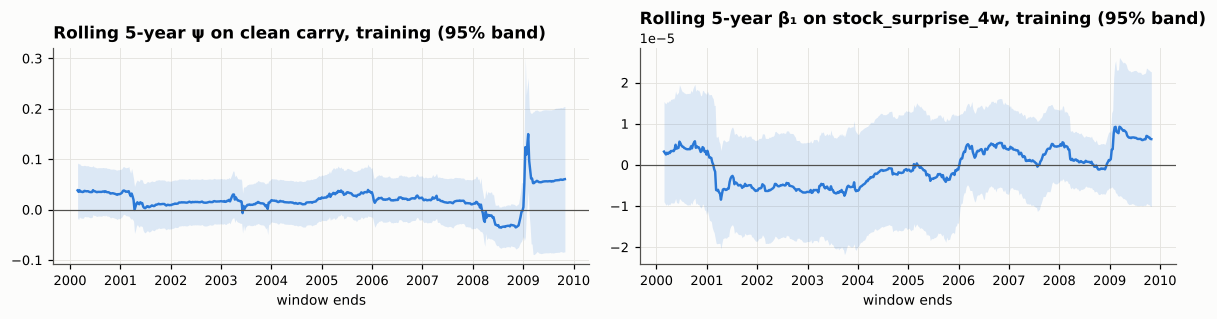

In [24]:
def rolling_coefs(d, ycol, xcols, names, win=ROLL_WIN):
    rec = []
    for i in range(win, len(d) + 1):
        r = ols(d.iloc[i - win:i], ycol, xcols)
        rec.append({"end": d.target_friday.iloc[i - 1], **{f"{n}": r.params[n] for n in names}, **{f"{n}_se": r.bse[n] for n in names}})
    return pd.DataFrame(rec).set_index("end")


RC = rolling_coefs(T, "y", M1_X, ["carry_clean", SURPRISE])
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, n, ttl in [(axes[0], "carry_clean", "ψ on clean carry"), (axes[1], SURPRISE, f"β₁ on {SURPRISE}")]:
    ax.plot(RC.index, RC[n], color=C["blue"]); ax.fill_between(RC.index, RC[n] - 1.96 * RC[n + "_se"], RC[n] + 1.96 * RC[n + "_se"], color=C["blue"], alpha=0.15, lw=0)
    ax.axhline(0, color=C["mute"], lw=0.8); ax.set_title(f"Rolling 5-year {ttl}, training (95% band)"); ax.set_xlabel("window ends")
savefig("07_rolling_coefficients_train")

### 6.3 Residual charts

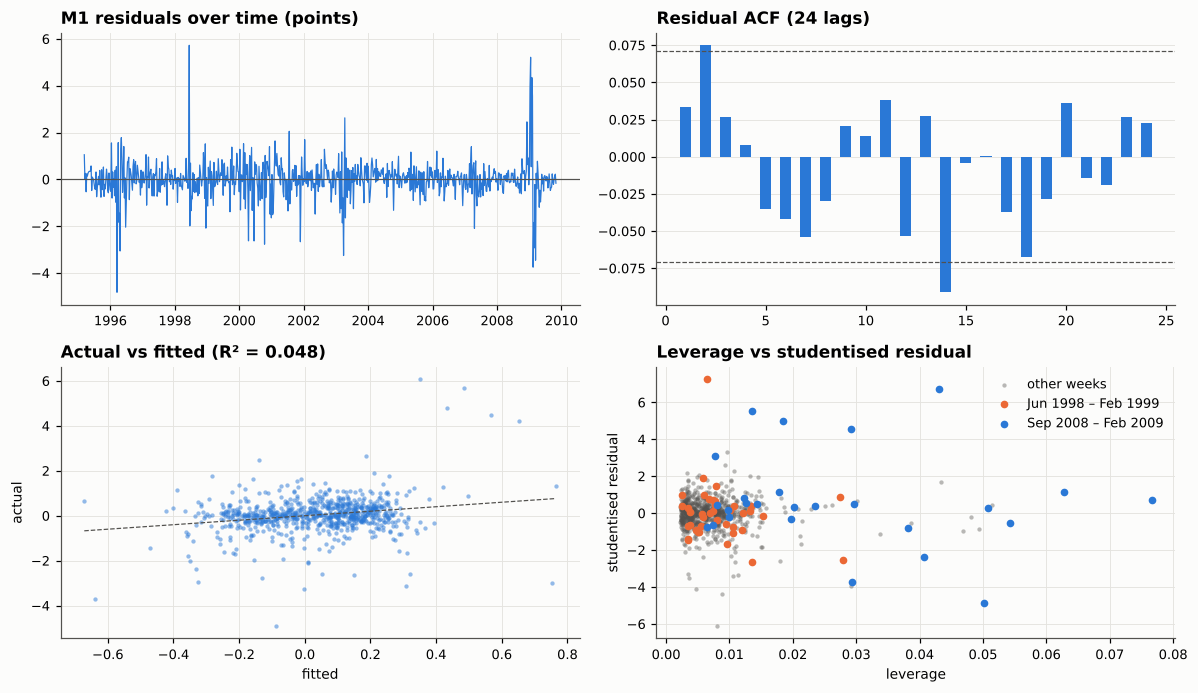

share of total leverage in the two event windows: 17% from 8% of the weeks


In [25]:
rfit = ols(T, "y", M1_X, hac=None); infl = rfit.get_influence()
fig, axes = plt.subplots(2, 2, figsize=(11, 6.4))
ax = axes[0, 0]; ax.plot(T.target_friday, rfit.resid, color=C["blue"], lw=0.8); ax.axhline(0, color=C["mute"], lw=0.8); ax.set_title("M1 residuals over time (points)")
ax = axes[0, 1]; ra = acf(rfit.resid, nlags=24)[1:]; ax.bar(range(1, 25), ra, color=C["blue"], width=0.55)
ax.axhline(band, color=C["mute"], ls="--", lw=0.8); ax.axhline(-band, color=C["mute"], ls="--", lw=0.8); ax.set_title("Residual ACF (24 lags)"); ax.grid(axis="x", visible=False)
ax = axes[1, 0]; ax.scatter(rfit.fittedvalues, T.y, s=8, color=C["blue"], alpha=0.5, lw=0)
lim = [rfit.fittedvalues.min(), rfit.fittedvalues.max()]; ax.plot(lim, lim, color=C["mute"], lw=0.8, ls="--")
ax.set_title(f"Actual vs fitted (R² = {rfit.rsquared:.3f})"); ax.set_xlabel("fitted"); ax.set_ylabel("actual")
ax = axes[1, 1]; lev, stud = infl.hat_matrix_diag, infl.resid_studentized_internal
is98 = (T.ev_1998 == 1).values; is08 = (T.ev_2008 == 1).values; oth = ~(is98 | is08)
ax.scatter(lev[oth], stud[oth], s=8, color=C["mute"], alpha=0.4, lw=0, label="other weeks")
ax.scatter(lev[is98], stud[is98], s=16, color=C["orange"], label="Jun 1998 – Feb 1999")
ax.scatter(lev[is08], stud[is08], s=16, color=C["blue"], label="Sep 2008 – Feb 2009")
ax.set_title("Leverage vs studentised residual"); ax.set_xlabel("leverage"); ax.set_ylabel("studentised residual"); ax.legend()
savefig("08_m1_residual_charts")
print(f"share of total leverage in the two event windows: {100 * lev[is98 | is08].sum() / lev.sum():.0f}% from {100 * (is98 | is08).mean():.0f}% of the weeks")

### 6.4 Robustness (training, M1)
Do ψ, β₁ and β₂ keep their sign and rough size? Effects are shown in cents per barrel at $70 oil so that a trader can read them.
The event dummies are in-sample only and are never forecasting regressors.


In [26]:
OIL = 70.0                                                # $/bbl used to express coefficients in cents
# cents/bbl next week for: 1 extra point of contango; a build 5 million bbl above normal; production up 100 thousand b/d
SC_PTS = {"psi": OIL, "beta1 surprise": 5000 * OIL, "beta2 production": 100 * OIL}       # target in points: 1 point = OIL cents
SC_USD = {"psi": OIL, "beta1 surprise": 5000 * 100.0, "beta2 production": 100 * 100.0}   # target in $: $1 = 100 cents; 1 point = $OIL/100
PSI_ROB = []                                              # raw psi of every row, for the Section 6 summary


def coef_row(r, names, scale=SC_PTS):
    out = {}
    for lab, n in names.items():
        out[lab] = f"{r.params[n] * scale[lab]:+.2f} ({r.tvalues[n]:.2f})" if n in r.params else "-"
    PSI_ROB.append(float(r.params[names["psi"]]))
    out["n"] = int(r.nobs)
    return out


NM = {"psi": "carry_clean", "beta1 surprise": SURPRISE, "beta2 production": "prod_chg_4w"}
rob = {"M1 baseline": coef_row(r_m1, NM)}
rob["0. with ev_1998 and ev_2008 dummies"] = coef_row(ols(T, "y", M1_X + ["ev_1998", "ev_2008"]), NM)
rob["1. without 1998"] = coef_row(ols(T[T.target_friday.dt.year != 1998], "y", M1_X), NM)
rob["2. excluding roll weeks"] = coef_row(ols(T[T.roll_week == 0], "y", [c for c in M1_X if c not in ("roll_week", "roll_x_carry")]), NM)
# 3. $ target: y_usd on the $ clean level
dU = DF.copy(); dU["roll_x_usd"] = dU.roll_week * dU.usd_clean
for i in range(1, 5):
    dU[f"yusd_lag{i}"] = Z.y_usd.shift(i).loc[DF.index]
usd_map = {"carry_clean": "usd_clean", "roll_x_carry": "roll_x_usd", **{f"y_lag{i}": f"yusd_lag{i}" for i in range(1, 5)}}
r_usd = ols(dU[TR], "y_usd", [usd_map.get(c, c) for c in M1_X])
rob["3. $ target (y_usd on usd_clean)"] = coef_row(r_usd, {**NM, "psi": "usd_clean"}, SC_USD)
# 4. thin window of 5 sessions
X5, _ = build_weekly(thin=5, check=False, verbose=False)
d5 = X5.loc[COMMON_START:]; d5 = d5[d5.split == "train"].copy()
for c in ["roll_week", "window_week"]:
    d5[c] = d5[c].astype(float)
rob["4. thin window = 5 sessions"] = coef_row(ols(d5, "y", M1_X), NM)
ROB = pd.DataFrame(rob).T.rename(columns={"psi": "1 extra point of contango", "beta1 surprise": "build 5 mb above normal",
                                          "beta2 production": "production +100 kb/d"})
ROB = save_table(ROB, "t6_robustness_M1_train")
print(f"effect on next week's spread, cents/bbl at ${OIL:.0f} oil (HAC t in brackets)"); print(ROB.to_string())
print(f"\nthin = 5: roll weeks {100 * X5.roll_week.mean():.1f}% (unchanged), Fridays in window {100 * X5.in_window.mean():.1f}% (was 17.5%), "
      f"sd of adjusted y {X5.y.std():.2f} (was {X.y.std():.2f})")

effect on next week's spread, cents/bbl at $70 oil (HAC t in brackets)
                                    1 extra point of contango build 5 mb above normal production +100 kb/d    n
M1 baseline                                      +3.06 (1.51)            +1.14 (0.73)        -1.84 (-1.33)  765
0. with ev_1998 and ev_2008 dummies              +1.90 (1.20)            +0.39 (0.28)        -1.72 (-1.17)  765
1. without 1998                                  +3.20 (1.42)            +0.99 (0.58)        -1.77 (-1.25)  713
2. excluding roll weeks                          +4.07 (1.60)            +1.83 (0.93)        -0.95 (-0.60)  589
3. $ target (y_usd on usd_clean)                 +2.52 (1.08)            +0.22 (0.29)        -0.93 (-1.08)  765
4. thin window = 5 sessions                      +3.88 (1.90)            +1.21 (0.79)        -0.66 (-0.86)  765

thin = 5: roll weeks 23.0% (unchanged), Fridays in window 23.7% (was 17.5%), sd of adjusted y 1.10 (was 1.10)


**Section 6 summary** (printed from the data)

In [27]:
rej = DIAG[DIAG["5% verdict"] == "reject"].index.get_level_values("test").tolist()
print(f"- Rejected at 5%: {rej or 'nothing'}.")
print("- Heteroskedasticity and fat tails are expected in this market; inference uses Newey-West errors and the sample is large (CLT).")
bgp = DIAG.loc[("autocorrelation", "Breusch-Godfrey (4)"), "p"]
print(f"- Residual autocorrelation (BG 4 lags p = {bgp:.3f}): " + ("present; Newey-West covers the standard errors, and BIC already had the chance to add lags of y." if bgp < 0.05 else "none detected."))
pairs = [(t, t.split(" (")[0] + ", robust (HAC Wald)") for t in DIAG.index.get_level_values("test") if t.startswith("Chow") and "robust" not in t]
pairs.append(("Ramsey RESET (powers 2-3)", "Ramsey RESET, robust (HAC Wald)"))
pairs.append(("Predictive failure, last 104 weeks", "Last 104 weeks, robust (HAC Wald on coefficient change)"))
P = DIAG.droplevel("group").p
flips = [f"{a.split(' (')[0].split(', last')[0]}: classical p = {P[a]:.3f}, robust p = {P[b]:.3f}" for a, b in pairs if P[a] < 0.05 <= P[b]]
print("- Classical rejections that disappear with robust errors: " + ("; ".join(flips) + ". These are changes in volatility, not in the coefficients, "
      "so no structural break or non-linearity is claimed." if flips else "none."))
ch = DIAG.loc["stability"]
print("- Stability: " + "; ".join(f"{t} p = {p:.3f}" for t, p in ch.p.items()) + ".")
psis = list(PSI_ROB)
print(f"- Robustness: psi is {'positive (no mean reversion) in every check' if min(psis) > 0 else 'not the same sign in every check'}, "
      f"from {min(psis):+.3f} to {max(psis):+.3f} (the $ row is in different units).")

- Rejected at 5%: ['White', 'Breusch-Pagan', 'ARCH-LM (4)', 'Jarque-Bera (skew 0.4, kurt 14.8)', 'Ramsey RESET (powers 2-3)', 'Chow at 2008-09-19 (706/59)', 'Predictive failure, last 104 weeks'].
- Heteroskedasticity and fat tails are expected in this market; inference uses Newey-West errors and the sample is large (CLT).
- Residual autocorrelation (BG 4 lags p = 0.175): none detected.
- Classical rejections that disappear with robust errors: Chow at 2008-09-19: classical p = 0.002, robust p = 0.840; Ramsey RESET: classical p = 0.026, robust p = 0.237; Predictive failure: classical p = 0.000, robust p = 0.760. These are changes in volatility, not in the coefficients, so no structural break or non-linearity is claimed.
- Stability: Chow at 2005-01-07 (513/252) p = 0.793; Chow at 2005-01-07, robust (HAC Wald) p = 0.923; Chow at 2008-09-19 (706/59) p = 0.002; Chow at 2008-09-19, robust (HAC Wald) p = 0.840; Predictive failure, last 104 weeks p = 0.000; Last 104 weeks, robust (HAC Wald on 

## 7. Validation and freeze

**Protocol.** At each origin *t* every model is re-estimated on rows whose target date is on or before Friday *t*, then forecasts *t+1*.
This is what a desk could have done in real time. The expanding window is the main scheme because it uses all the history; a 260-week
rolling window is the robustness scheme, in case old data no longer describes the market.
Lasso coefficients are refitted every week and λ is re-chosen every 52 weeks by `TimeSeriesSplit(5)` inside the current window.

**Comparing forecasts.** For each pair of models the weekly difference in squared errors is regressed on a constant with
Newey–West errors; the t-statistic tests, one-sided, whether the first model has the lower error. We use this plain test because it needs
only a t-test and robust errors. For a larger model against a smaller one nested in it, it leans against the larger model, so
"no significant gain" is the cautious reading.

**Correct sign.** `% correct sign` is shown next to the share of "up" forecasts and the score of always guessing "up".
A model that nearly always says "up" scores above 50% whenever the spread mostly widened, without any skill.


In [28]:
def oos_forecasts(eval_mask, b2_x, m1_x, window="expanding", pool=POOL, verbose=False, frame=None):
    """One-step-ahead forecasts for B1, B2, M1, M2 on the rows in eval_mask. Row i is fitted on rows < i only
    (row i-1 has target date = Friday i, so everything in the fit was public at the forecast origin)."""
    DF_ = DF if frame is None else frame                    # frame: same rows, other units (Section 8.3)
    y = DF_.y.values
    A2 = np.c_[np.ones(len(DF_)), DF_[b2_x].values.astype(float)]
    A1 = np.c_[np.ones(len(DF_)), DF_[m1_x].values.astype(float)]
    P = DF_[pool].values.astype(float)
    pos = np.where(np.asarray(eval_mask))[0]
    F = pd.DataFrame(0.0, index=DF_.index[pos], columns=["B1", "B2", "M1", "M2"])
    alpha = None
    for n, i in enumerate(pos):
        lo = 0 if window == "expanding" else max(0, i - ROLL_WIN)
        F.iat[n, 1] = A2[i] @ np.linalg.lstsq(A2[lo:i], y[lo:i], rcond=None)[0]
        F.iat[n, 2] = A1[i] @ np.linalg.lstsq(A1[lo:i], y[lo:i], rcond=None)[0]
        if n % LASSO_RESELECT == 0:
            alpha, _ = fit_lasso_cv(P[lo:i], y[lo:i])
            if verbose:
                print(f"  {DF_.index[i].date()}: lambda re-chosen = {alpha:.4f}")
        m2 = make_pipeline(StandardScaler(), Lasso(alpha=alpha, max_iter=20000)).fit(P[lo:i], y[lo:i])
        F.iat[n, 3] = m2.predict(P[i:i + 1])[0]
    return F


MODELS = ["B1", "B2", "M1", "M2"]                         # also the order of simplicity
PAIRS = [("B2", "B1"), ("M1", "B2"), ("M2", "M1"), ("M1", "B1"), ("M2", "B1")]
QUESTION = {("B2", "B1"): "Does the level of carry help?", ("M1", "B2"): "Do fundamentals add beyond the curve?",
            ("M2", "M1"): "Does automatic selection beat theory?", ("M1", "B1"): "M1 vs the naive benchmark", ("M2", "B1"): "M2 vs the naive benchmark"}


def metrics(F, mask=None):
    d = DF.loc[F.index]
    if mask is not None:
        F, d = F[mask.values], d[mask.values]
    act_c = 100 * d.y_usd                                 # what the spread earned, cents/bbl
    up_base = 100 * (d.y[d.y != 0] > 0).mean()            # score of always guessing "up"
    rows = {}
    for m in F.columns:
        e = d.y - F[m]; ec = act_c - F[m] * d.CL1         # forecast in cents = points x CL1
        nz = (F[m] != 0) & (d.y != 0)
        rows[m] = {"MSE": (e ** 2).mean(), "RMSE (points)": np.sqrt((e ** 2).mean()), "MAE (points)": e.abs().mean(),
                   "RMSE (cents)": np.sqrt((ec ** 2).mean()), "MAE (cents)": ec.abs().mean(),
                   "R2_OS vs B1": 1 - (e ** 2).sum() / (d.y ** 2).sum(),
                   "R2_OS vs B1 (cents)": 1 - (ec ** 2).sum() / (act_c ** 2).sum(),      # same forecasts, scored in cents
                   "% correct sign": 100 * (np.sign(F[m][nz]) == np.sign(d.y[nz])).mean() if nz.any() else np.nan,
                   "% forecasts up": 100 * (F[m] > 0).mean() if (F[m] != 0).any() else np.nan,
                   "always-up % correct": up_base}
    return pd.DataFrame(rows).T


def compare(F, mask=None):
    """Loss differential d = e2_bench - e2_model regressed on a constant with Newey-West errors; one-sided test that the model is better.
    This is the plain test on the error difference; it is conservative for nested models."""
    d = DF.loc[F.index]
    if mask is not None:
        F, d = F[mask.values], d[mask.values]
    rows = {}
    for mod, ben in PAIRS:
        dl = (d.y - F[ben]) ** 2 - (d.y - F[mod]) ** 2
        r = sm.OLS(dl.values, np.ones(len(dl))).fit(cov_type="HAC", cov_kwds={"maxlags": NW})
        t = float(r.tvalues[0])
        rows[f"{mod} vs {ben}"] = {"question": QUESTION[(mod, ben)], "MSE ratio": ((d.y - F[mod]) ** 2).mean() / ((d.y - F[ben]) ** 2).mean(),
                                   "R2_OS": 1 - ((d.y - F[mod]) ** 2).sum() / ((d.y - F[ben]) ** 2).sum(),
                                   "HAC t": t, "one-sided p": float(st.norm.sf(t))}
    return pd.DataFrame(rows).T


print("validation, expanding window:"); F_VAL = oos_forecasts(VA, B2_X, M1_X, "expanding", verbose=True)
F_VAL_ROLL = oos_forecasts(VA, B2_X, M1_X, "rolling")
F_VAL.to_csv(f"{OUT}/forecasts_validation_expanding.csv")

validation, expanding window:
  2009-10-30: lambda re-chosen = 0.0315


  2010-10-29: lambda re-chosen = 0.0301
  2011-10-28: lambda re-chosen = 0.0411


  2012-10-26: lambda re-chosen = 0.0323
  2013-10-25: lambda re-chosen = 0.0384


  2014-10-24: lambda re-chosen = 0.0373
  2015-10-23: lambda re-chosen = 0.0475


  2016-10-21: lambda re-chosen = 0.0389


In [29]:
M_VAL = save_table(metrics(F_VAL), "t7_validation_metrics_expanding"); M_VAL_ROLL = metrics(F_VAL_ROLL)
C_VAL = save_table(compare(F_VAL), "t7_validation_comparisons")
print("VALIDATION, expanding window (Nov 2009 - Feb 2017, 382 weeks)"); print(M_VAL.to_string(float_format=lambda v: f"{v:.3f}"))
print("\nThe three comparisons, then every model against B1"); print(C_VAL.to_string(float_format=lambda v: f"{v:.3f}"))
print("\nValidation MSE, rolling 260 weeks vs expanding:")
print(pd.DataFrame({"expanding": M_VAL.MSE, "rolling": M_VAL_ROLL.MSE, "rolling / expanding": M_VAL_ROLL.MSE / M_VAL.MSE}).to_string(float_format=lambda v: f"{v:.3f}"))

VALIDATION, expanding window (Nov 2009 - Feb 2017, 382 weeks)
     MSE  RMSE (points)  MAE (points)  RMSE (cents)  MAE (cents)  R2_OS vs B1  R2_OS vs B1 (cents)  % correct sign  % forecasts up  always-up % correct
B1 0.125          0.354         0.204        21.150       12.853        0.000                0.000             NaN             NaN               54.737
B2 0.130          0.361         0.216        21.628       13.534       -0.042               -0.046          50.000          91.623               54.737
M1 0.135          0.367         0.244        23.582       16.511       -0.079               -0.243          52.895          64.660               54.737
M2 0.125          0.353         0.217        21.522       13.971        0.003               -0.036          52.368          74.084               54.737

The three comparisons, then every model against B1
                                       question MSE ratio  R2_OS  HAC t one-sided p
B2 vs B1          Does the level of carry 

### 7.1 Choosing the winner (rule fixed before validation was run)
Lowest validation MSE wins. If a simpler model (B1 < B2 < M1 < M2) is within 1% of that MSE, the simpler one is chosen: a gain that small
is not worth the extra complexity, and it is unlikely to survive on new data.


In [30]:
best = M_VAL.MSE.idxmin()
WINNER = next(m for m in MODELS if M_VAL.MSE[m] <= 1.01 * M_VAL.MSE[best])
print(f"lowest validation MSE: {best} ({M_VAL.MSE[best]:.4f}). Simplest model within 1%: {WINNER} ({M_VAL.MSE[WINNER]:.4f}).")
SIGNAL = WINNER if WINNER != "B1" else "M1"
print(f"WINNER = {WINNER}." + ("" if WINNER != "B1" else " B1 gives no signal, so the trading rule uses M1 as an illustration only."))

lowest validation MSE: M2 (0.1248). Simplest model within 1%: B1 (0.1251).
WINNER = B1. B1 gives no signal, so the trading rule uses M1 as an illustration only.


### 7.2 Expanding or rolling? Chow at the pre-named date 28 Nov 2014 (train + validation)
Rule: the rolling window replaces the expanding window only if the Chow test rejects stability at 5% **and** the rolling window has
the lower validation MSE for the model that drives the signal. Otherwise expanding (the main scheme) stays.

In [31]:
TV = DF[TR | VA]
ref_x = B2_X if SIGNAL == "B2" else M1_X
Fc, pc, n1, n2 = chow(TV, "y", ref_x, CHOW_TRVAL)
print(f"Chow at {CHOW_TRVAL} on {'B2' if SIGNAL == 'B2' else 'M1'} ({n1}/{n2} rows): F = {Fc:.2f}, p = {pc:.3f}")
roll_better = M_VAL_ROLL.MSE[SIGNAL] < M_VAL.MSE[SIGNAL]
WINDOW = "rolling" if (pc < 0.05 and roll_better) else "expanding"
print(f"rolling has lower validation MSE for {SIGNAL}: {roll_better} -> WINDOW = {WINDOW}")
F_VAL_USE = F_VAL_ROLL if WINDOW == "rolling" else F_VAL

alpha_tv, m2_tv = fit_lasso_cv(TV[POOL].values, TV.y.values)
coef_tv = pd.Series(m2_tv[-1].coef_, index=POOL)
LASSO_KEPT_TV = list(coef_tv[coef_tv != 0].index)
print(f"\nLasso at the end of validation (lambda = {alpha_tv:.4f}) keeps: {LASSO_KEPT_TV or 'none'}  | on training it kept: {LASSO_KEPT_TRAIN or 'none'}")

Chow at 2014-11-28 on M1 (1029/118 rows): F = 1.21, p = 0.298
rolling has lower validation MSE for M1: False -> WINDOW = expanding

Lasso at the end of validation (lambda = 0.0384) keeps: ['carry_clean', 'roll_week', 'window_week', 'y_lag1', 'y_lag2', 'cl1_mom4']  | on training it kept: ['carry_clean', 'prod_chg_4w', 'roll_week', 'window_week', 'roll_x_carry', 'y_lag1', 'y_lag2', 'y_lag4', 'cl1_mom4', 'comm_net', 'VIX', 'DXY_ret']


### 7.3 Trading threshold k, chosen on validation

- Signal in cents/bbl = forecast × CL1. Above +k: long CL2 / short CL1. Below −k: the reverse. Otherwise flat. k = 0 trades the sign.
- P&L = position × roll-adjusted $ change (`y_usd`), so the roll days already earn zero.
- Costs per side: charged on every entry and exit (a flip is two sides), twice more for each roll held through, and on the final exit.
- **No-trade check.** If every threshold loses money after costs on validation, the signal is marked **not tradeable**. A k is still recorded so that Section 9 can show what the rule would have done, but only as an illustration.
- **Sharpe ratio** = mean weekly net P&L ÷ its standard deviation × √52 (annualised). No risk-free rate is subtracted: a futures spread
  needs no capital outlay, so its P&L is already an excess return.


In [32]:
def trade(index, position=None, forecast=None, k=0.0, cost=COST_BASE):
    d = DF.loc[index]
    if position is None:
        sig = forecast.loc[index] * d.CL1                                # cents/bbl
        position = np.where(sig > k, 1.0, np.where(sig < -k, -1.0, 0.0))
    pos = np.asarray(position, float)
    sides = np.abs(np.diff(np.r_[0.0, pos]))                             # entry 1, exit 1, flip 2
    sides[-1] += abs(pos[-1])                                            # close out at the end
    sides += 2 * np.abs(pos) * d.roll_week.values                        # out at L-3, back in at L+1
    gross = pos * 100 * d.y_usd.values
    return pd.DataFrame({"pos": pos, "gross": gross, "sides": sides, "net": gross - cost * sides}, index=index)


def pnl_stats(tr, mask=None):
    if mask is not None:
        tr = tr[mask.values]
    on = tr.pos != 0
    cum = tr.net.cumsum()
    return {"weeks traded": int(on.sum()), "% of weeks": 100 * on.mean(), "gross (cents)": tr.gross.sum(), "net (cents)": tr.net.sum(),
            "net per week": tr.net.mean(), "hit rate when traded, %": 100 * (tr.gross[on] > 0).mean() if on.any() else np.nan,
            "sides traded": tr.sides.sum(), "worst week": tr.net.min(), "max drawdown": (cum - cum.cummax().clip(lower=0)).min(),
            "Sharpe (mean/sd x sqrt 52)": tr.net.mean() / tr.net.std() * np.sqrt(52) if tr.net.std() > 0 else np.nan}


kt = pd.DataFrame({k: pnl_stats(trade(F_VAL_USE.index, forecast=F_VAL_USE[SIGNAL], k=k)) for k in K_GRID}).T
kt.index.name = "k (cents)"
save_table(kt, "t7_validation_threshold")
print(f"validation, signal = {SIGNAL}, {WINDOW} window, cost {COST_BASE:.0f} cent per side"); print(kt.to_string(float_format=lambda v: f"{v:.2f}"))
elig = kt[kt["weeks traded"] >= MIN_TRADED]
assert len(elig), "no threshold trades at least 26 validation weeks"
K_STAR = float(elig["net (cents)"].idxmax())
print(f"\neligible (at least {MIN_TRADED} weeks traded): k in {list(elig.index)} -> k = {K_STAR:g} cents (best net validation P&L: {elig['net (cents)'].max():.1f} cents)")
TRADEABLE = bool(elig["net (cents)"].max() > 0)
print("NO-TRADE CHECK:", f"k = {K_STAR:g} makes money after costs on validation, so the rule may be tested." if TRADEABLE else
      f"every threshold loses money after costs on validation (best: {elig['net (cents)'].max():.0f} cents). The {SIGNAL} signal is NOT TRADEABLE; "
      f"k = {K_STAR:g} is kept only to illustrate the rule in Section 9.")

validation, signal = M1, expanding window, cost 1 cent per side
           weeks traded  % of weeks  gross (cents)  net (cents)  net per week  hit rate when traded, %  sides traded  worst week  max drawdown  Sharpe (mean/sd x sqrt 52)
k (cents)                                                                                                                                                                 
0                382.00      100.00         354.00      -130.00         -0.34                    52.88        484.00     -122.00       -559.00                       -0.12
2                350.00       91.62         327.00      -121.00         -0.32                    53.71        448.00     -122.00       -580.00                       -0.11
5                317.00       82.98         223.00      -173.00         -0.45                    52.68        396.00     -122.00       -543.00                       -0.17
10               174.00       45.55         126.00      -106.00         -0.28    

### 7.4 Freeze
Everything the test needs is written to `outputs/freeze.json`. Section 8 reads its settings from this file and nothing else.

**Written once.** If the file already exists and the settings are the same, it is left alone and keeps its original time stamp.
If any setting differs, the notebook **stops** rather than overwrite it: changing a setting after the test has been seen has to be a deliberate act
(delete the file by hand) and has to be reported. We freeze because a test is only a test if nothing is tuned on it. The time stamp inside the file records when the settings were fixed.


In [33]:
freeze = {
    "frozen_at": dt.datetime.now().isoformat(timespec="seconds"),
    "winner": WINNER, "signal_model": SIGNAL, "window": WINDOW, "k_cents": K_STAR, "tradeable_on_validation": TRADEABLE,
    "b2_p": int(B2_P), "b2_terms": B2_X, "m1_terms": M1_X, "surprise_version": SURPRISE,
    "lasso": {"pool": POOL, "cv": f"TimeSeriesSplit({LASSO_SPLITS})", "reselect_every_weeks": LASSO_RESELECT, "standardised": True},
    "newey_west_lags": NW, "rolling_window_weeks": ROLL_WIN, "cost_cents_per_side": COST_BASE,
    "validation_mse": {m: float(M_VAL.MSE[m]) for m in MODELS},
    "split": {"train_end": TRAIN_END, "validation_end": VAL_END, "last_target": LAST_FRI},
}


def same_setting(a, b):
    if isinstance(a, dict) and isinstance(b, dict):
        return a.keys() == b.keys() and all(same_setting(a[k_], b[k_]) for k_ in a)
    if isinstance(a, float) or isinstance(b, float):
        return bool(np.isclose(a, b, rtol=1e-8, atol=1e-12))
    return a == b


if os.path.exists(FREEZE):
    with open(FREEZE) as f:
        old = json.load(f)
    changed = [k_ for k_ in freeze if k_ != "frozen_at" and k_ in old and not same_setting(freeze[k_], old[k_])]
    if changed:
        raise RuntimeError(f"freeze.json from {old.get('frozen_at')} has different settings for {changed}. It is NOT overwritten. "
                           "If the change is intended, delete the file by hand, re-run, and report that the test was re-scored.")
    added = [k_ for k_ in freeze if k_ not in old]
    freeze["frozen_at"] = old["frozen_at"]                               # keep the original time stamp
    print(f"freeze.json unchanged since {old['frozen_at']}: kept" + (f" (new fields recorded: {added})" if added else "") + ".")
    if added:
        with open(FREEZE, "w") as f:
            json.dump(freeze, f, indent=2)
else:
    with open(FREEZE, "w") as f:
        json.dump(freeze, f, indent=2)
    print("freeze.json written for the first time.")
print(json.dumps({k: v for k, v in freeze.items() if k != "lasso"}, indent=2))

freeze.json unchanged since 2026-11-16T18:24:27: kept.
{
  "frozen_at": "2026-11-16T18:24:27",
  "winner": "B1",
  "signal_model": "M1",
  "window": "expanding",
  "k_cents": 10.0,
  "tradeable_on_validation": false,
  "b2_p": 0,
  "b2_terms": [
    "carry_clean"
  ],
  "m1_terms": [
    "carry_clean",
    "stock_surprise_4w",
    "prod_chg_4w",
    "roll_week",
    "window_week"
  ],
  "surprise_version": "stock_surprise_4w",
  "newey_west_lags": 7,
  "rolling_window_weeks": 260,
  "cost_cents_per_side": 1.0,
  "validation_mse": {
    "B1": 0.12513310813332484,
    "B2": 0.13034086921539673,
    "M1": 0.13499248855113846,
    "M2": 0.12475999734104344
  },
  "split": {
    "train_end": "2009-10-30",
    "validation_end": "2017-02-24",
    "last_target": "2024-06-28"
  }
}


### 7.5 Diagnostics repeated on the frozen specification, refitted to train + validation

In [34]:
DIAG_TV, _ = diagnostics(TV, "y", ref_x, CHOW_TRAIN + [CHOW_TRVAL])
save_table(DIAG_TV, "t7_diagnostics_train_validation")
print(f"{'B2' if SIGNAL == 'B2' else 'M1'} on train + validation ({len(TV)} rows)")
print(DIAG_TV[["stat", "p", "5% verdict"]].to_string(float_format=lambda v: f"{v:.3f}"))
r_tv = ols(TV, "y", ref_x)
print(); print(r_tv.summary().tables[1])

M1 on train + validation (1147 rows)
                                                                                stat     p     5% verdict
group              test                                                                                  
autocorrelation    Breusch-Godfrey (4)                                         9.349 0.053  do not reject
                   Breusch-Godfrey (12)                                       19.056 0.087  do not reject
                   Ljung-Box on residuals (12)                                18.654 0.097  do not reject
heteroskedasticity White                                                     271.928 0.000         reject
                   Breusch-Pagan                                              35.364 0.000         reject
                   ARCH-LM (4)                                               174.078 0.000         reject
                   Goldfeld-Quandt at 2005-01-07                               0.567 0.000         reject
normality


                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 0.1013      0.027      3.739      0.000       0.048       0.154
carry_clean           0.0351      0.025      1.386      0.166      -0.015       0.085
stock_surprise_4w  2.017e-06   2.82e-06      0.716      0.474    -3.5e-06    7.54e-06
prod_chg_4w          -0.0002      0.000     -1.247      0.213      -0.000    9.97e-05
roll_week            -0.1646      0.039     -4.252      0.000      -0.241      -0.089
window_week          -0.2658      0.055     -4.832      0.000      -0.374      -0.158


**Section 7 summary** (printed from the data)

In [35]:
for pair in ["B2 vs B1", "M1 vs B2", "M2 vs M1"]:
    c = C_VAL.loc[pair]
    print(f"- {c.question} {pair}: MSE ratio {c['MSE ratio']:.3f}, R2_OS {100 * c['R2_OS']:+.1f}%, one-sided p = {c['one-sided p']:.3f} -> " + ("yes on validation." if c["one-sided p"] < 0.05 else "no significant gain on validation."))
cb = C_VAL.loc["M2 vs B1"]
print(f"- M2 beating M1 is not M2 beating the benchmark: M1 was itself worse than no change. M2 vs B1: MSE ratio {cb['MSE ratio']:.3f}, "
      f"one-sided p = {cb['one-sided p']:.3f}.")
print(f"- Winner by the rule fixed in advance: {WINNER}. Window: {WINDOW}. Threshold: k = {K_STAR:g} cents"
      + ("" if TRADEABLE else " (illustration only: no threshold made money on validation)") + f". Written to {FREEZE}.")

- Does the level of carry help? B2 vs B1: MSE ratio 1.042, R2_OS -4.2%, one-sided p = 0.904 -> no significant gain on validation.
- Do fundamentals add beyond the curve? M1 vs B2: MSE ratio 1.036, R2_OS -3.6%, one-sided p = 0.771 -> no significant gain on validation.
- Does automatic selection beat theory? M2 vs M1: MSE ratio 0.924, R2_OS +7.6%, one-sided p = 0.014 -> yes on validation.
- M2 beating M1 is not M2 beating the benchmark: M1 was itself worse than no change. M2 vs B1: MSE ratio 0.997, one-sided p = 0.466.
- Winner by the rule fixed in advance: B1. Window: expanding. Threshold: k = 10 cents (illustration only: no threshold made money on validation). Written to outputs/freeze.json.


## 8. Test (frozen settings)

Target weeks 3 Mar 2017 – 28 Jun 2024, 383 weeks. All settings come from `freeze.json`. **Do not change anything above after reading this section.**

**Which table to read first.** The headline is the test over **all 383 weeks**, because that is what was fixed before the test.
The 13 weeks of March–May 2020 (negative prices, storage full) hold almost all of its squared error in points, so that table is decided by
two or three weeks and its significance tests have little power. The same forecasts are therefore also scored **without March–May 2020**
(370 weeks) as a sensitivity check. We chose that second table after seeing the test: Section 0 named the window, but only for
in-sample robustness. The models are the same in both tables: they are still fitted on the 2020 weeks afterwards, as they would have been in real time.

**Added after the test was first scored (post-test).** None of these changes a frozen setting, a forecast or a headline number, and none is
evidence for a model.
- the separate scoring without March–May 2020 (this section and Section 9);
- the dollar re-estimation (Section 8.3);
- the two mean-reversion (B2) trading rules and the block bootstrap (Sections 9 and 9.1);
- R²_OS in cents, the always-"up" baseline, the slope by sub-period (Section 9.0) and the breakdown of M1's errors by type of week (Section 9.2).

**Order of work.** The freeze cell writes `freeze.json` before this section runs, and this section refuses to run without it.
The file and the test outputs were committed together, so the time stamp inside the file is the record of the order. Re-running cannot
change the frozen settings: the notebook stops if they differ.


In [36]:
assert os.path.exists(FREEZE), "freeze.json missing: run Section 7 first"
with open(FREEZE) as f:
    FZ = json.load(f)
print("frozen at", FZ["frozen_at"], "| winner", FZ["winner"], "| window", FZ["window"], "| k", FZ["k_cents"])
F_TEST = oos_forecasts(TE, FZ["b2_terms"], FZ["m1_terms"], FZ["window"], pool=FZ["lasso"]["pool"])
F_TEST.to_csv(f"{OUT}/forecasts_test.csv")
NO20 = (DF.loc[F_TEST.index, "ev_2020"] == 0)

M_TEST = save_table(metrics(F_TEST), "t8_test_metrics"); C_TEST = save_table(compare(F_TEST), "t8_test_comparisons")
M_TEST_X = save_table(metrics(F_TEST, NO20), "t8_test_metrics_ex2020"); C_TEST_X = save_table(compare(F_TEST, NO20), "t8_test_comparisons_ex2020")
y2 = DF.loc[F_TEST.index, "y"] ** 2
SHARE20, SHARE_TOP = 100 * y2[~NO20.values].sum() / y2.sum(), 100 * y2.max() / y2.sum()
print(f"\nShare of the test squared error (B1) in the {int((~NO20).sum())} weeks of Mar-May 2020: {SHARE20:.0f}%; in the single largest week: {SHARE_TOP:.0f}%.")
print(f"\nHEADLINE (fixed before the test): TEST, all 383 weeks, {FZ['window']} window (decided by Mar-May 2020; read the tests with care)")
print(M_TEST.to_string(float_format=lambda v: f"{v:.3f}"))
print(); print(C_TEST.to_string(float_format=lambda v: f"{v:.3f}"))
print(f"\nSENSITIVITY (post-test): TEST without Mar-May 2020 ({int(NO20.sum())} weeks)"); print(M_TEST_X.to_string(float_format=lambda v: f"{v:.3f}"))
print(); print(C_TEST_X.to_string(float_format=lambda v: f"{v:.3f}"))


frozen at 2026-11-16T18:24:27 | winner B1 | window expanding | k 10.0



Share of the test squared error (B1) in the 13 weeks of Mar-May 2020: 98%; in the single largest week: 47%.

HEADLINE (fixed before the test): TEST, all 383 weeks, expanding window (decided by Mar-May 2020; read the tests with care)
     MSE  RMSE (points)  MAE (points)  RMSE (cents)  MAE (cents)  R2_OS vs B1  R2_OS vs B1 (cents)  % correct sign  % forecasts up  always-up % correct
B1 3.418          1.849         0.382        36.673       15.963        0.000                0.000             NaN             NaN               55.263
B2 3.437          1.854         0.377        36.601       15.944       -0.006                0.004          57.895          87.990               55.263
M1 3.472          1.863         0.435        38.266       19.648       -0.016               -0.089          49.474          63.969               55.263
M2 4.800          2.191         0.440        41.063       17.620       -0.404               -0.254          52.368          80.418               55.263

     

### 8.1 Cumulative SSE difference (Goyal–Welch)
A rising line means the first-named model is forecasting better than the second. Flat means no difference.

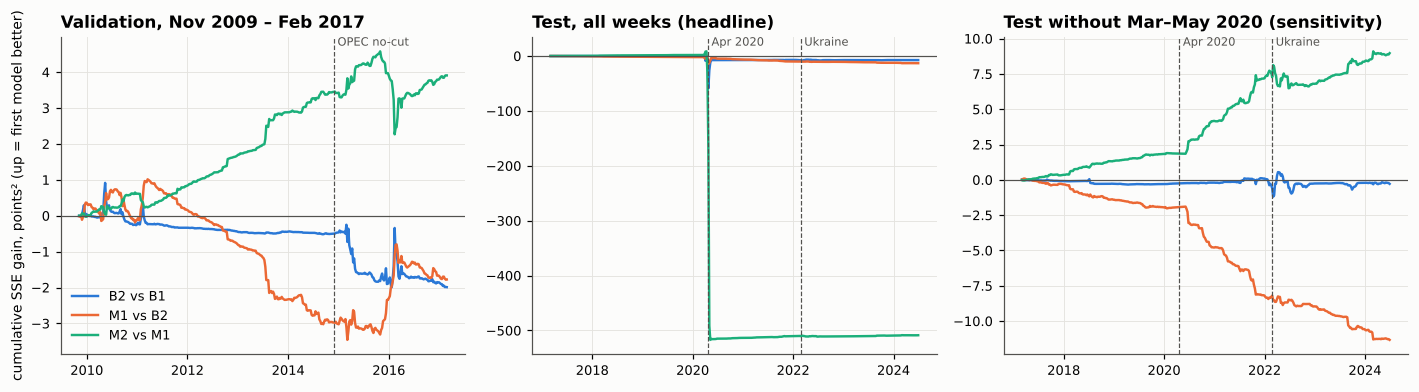

In [37]:
def cum_sse(F, mod, ben):
    d = DF.loc[F.index]
    return pd.Series(((d.y - F[ben]) ** 2 - (d.y - F[mod]) ** 2).cumsum().values, index=d.target_friday.values)


cols = {"B2 vs B1": C["blue"], "M1 vs B2": C["orange"], "M2 vs M1": C["aqua"]}
F_TEST_X = F_TEST[NO20.values]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, F, name in [(axes[0], F_VAL_USE, "Validation, Nov 2009 – Feb 2017"), (axes[1], F_TEST, "Test, all weeks (headline)"),
                    (axes[2], F_TEST_X, "Test without Mar–May 2020 (sensitivity)")]:
    for lab, col in cols.items():
        mod, ben = lab.split(" vs ")
        s_ = cum_sse(F, mod, ben); ax.plot(s_.index, s_.values, color=col, label=lab)
    ax.axhline(0, color=C["mute"], lw=0.8)
    lo_, hi_ = ax.get_ylim()
    for ev, txt in [("2014-11-28", "OPEC no-cut"), ("2020-04-20", "Apr 2020"), ("2022-02-24", "Ukraine")]:
        if DF.loc[F.index[0], "target_friday"] <= pd.Timestamp(ev) <= DF.loc[F.index[-1], "target_friday"]:
            ax.axvline(pd.Timestamp(ev), color=C["mute"], lw=0.8, ls="--"); ax.text(pd.Timestamp(ev), hi_, " " + txt, fontsize=7.5, color=C["mute"], va="top")
    ax.set_title(name); ax.xaxis.set_major_locator(mdates.YearLocator(2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[0].set_ylabel("cumulative SSE gain, points² (up = first model better)"); axes[0].legend(loc="lower left")
savefig("09_cumulative_sse")

### 8.2 Contribution chart for M1 (illustration: M1 is not the winner)
Coefficients from the fit on train + validation, applied to each test week: which variable is pushing the forecast?
These are **fixed** coefficients. The forecasts scored in Section 8 use coefficients re-estimated every week, so this chart shows what drives
the forecast, not the exact numbers that were scored.


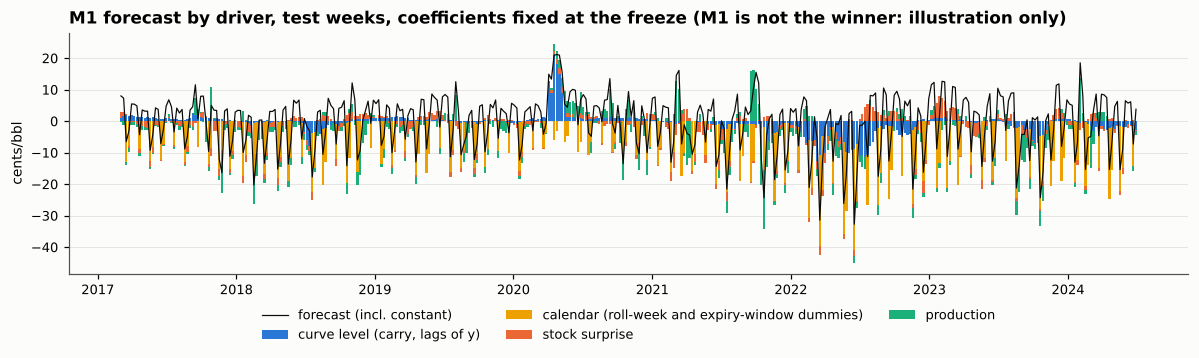

share of the week-to-week movement in the M1 forecast (variance of each part, cents):
curve level (carry, lags of y)                    13%
calendar (roll-week and expiry-window dummies)    68%
stock surprise                                     4%
production                                        15%


In [38]:
r_c = ols(TV, "y", FZ["m1_terms"]); dT = DF[TE]
contrib = dT[FZ["m1_terms"]].astype(float) * r_c.params[FZ["m1_terms"]]
grp = {"curve level (carry, lags of y)": [c for c in FZ["m1_terms"] if c in ("carry_clean", "roll_x_carry") or c.startswith("y_lag")],
       "calendar (roll-week and expiry-window dummies)": [c for c in FZ["m1_terms"] if c in ("roll_week", "window_week")],
       "stock surprise": [FZ["surprise_version"]], "production": ["prod_chg_4w"]}
G = pd.DataFrame({g: contrib[c].sum(axis=1) for g, c in grp.items()}) * dT[["CL1"]].values       # cents/bbl
fig, ax = plt.subplots(figsize=(11, 3.4))
bp_, bn_ = np.zeros(len(G)), np.zeros(len(G))
for g, col in zip(G.columns, [C["blue"], C["yellow"], C["orange"], C["aqua"]]):
    v = G[g].values; base = np.where(v >= 0, bp_, bn_)
    ax.bar(dT.target_friday, v, bottom=base, width=6, color=col, label=g, lw=0)
    bp_ += np.where(v >= 0, v, 0); bn_ += np.where(v < 0, v, 0)
tot = G.sum(axis=1) + r_c.params["const"] * dT.CL1
ax.plot(dT.target_friday, tot, color=C["ink"], lw=0.8, label="forecast (incl. constant)")
ax.set_title("M1 forecast by driver, test weeks, coefficients fixed at the freeze" + ("" if FZ["winner"] == "M1" else " (M1 is not the winner: illustration only)"))
ax.set_ylabel("cents/bbl"); ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1)); ax.grid(axis="x", visible=False)
savefig("10_contribution_chart_M1")
print("share of the week-to-week movement in the M1 forecast (variance of each part, cents):")
print((100 * G.var() / G.var().sum()).round(0).astype(int).astype(str).add("%").to_string())

### 8.3 The same test in dollars: does the choice of units change the answer?
The models forecast the change in carry in **points (% of CL1)**, but a calendar spread earns **dollars per barrel**. The two differ most when CL1 is
very low (April 2020), where a small dollar move is a very large percentage move. So the whole exercise is repeated with everything in cents per barrel:
target = roll-adjusted change in the $ spread, level = clean $ spread, lags and the roll interaction in cents. Same four models, same windows, same rules.

The points specification stays the headline because it was fixed before the test was run. This section was added **after the test had been seen
(post-test)**: it only asks whether the conclusion depends on the unit.

Do not confuse it with the cents columns in the tables above. Those take the frozen points forecasts and convert them to cents (forecast × CL1).
Here the models themselves are re-estimated on a dollar target, so the numbers differ.


In [39]:
DFU = DF.copy()                                              # same rows and columns, dollar units (cents/bbl)
DFU["y"] = 100 * DF.y_usd
DFU["carry_clean"] = 100 * DF.usd_clean
DFU["roll_x_carry"] = DF.roll_week * DFU.carry_clean
for i in range(1, 5):
    DFU[f"y_lag{i}"] = 100 * Z.y_usd.shift(i).loc[DF.index]
assert DFU[FZ["lasso"]["pool"] + ["y"]].notna().all().all()

FU_VAL = oos_forecasts(VA, FZ["b2_terms"], FZ["m1_terms"], FZ["window"], pool=FZ["lasso"]["pool"], frame=DFU)
FU_TEST = oos_forecasts(TE, FZ["b2_terms"], FZ["m1_terms"], FZ["window"], pool=FZ["lasso"]["pool"], frame=DFU)


def usd_table(F):
    act = DFU.loc[F.index, "y"]
    mse = pd.Series({m: ((act - F[m]) ** 2).mean() for m in MODELS})
    t = {}
    for m in MODELS[1:]:
        dl = (act ** 2 - (act - F[m]) ** 2).values
        t[m] = float(sm.OLS(dl, np.ones(len(dl))).fit(cov_type="HAC", cov_kwds={"maxlags": NW}).tvalues[0])
    return pd.DataFrame({"RMSE (cents)": np.sqrt(mse), "R2_OS vs B1, %": 100 * (1 - mse / mse["B1"]), "HAC t vs B1": pd.Series(t)})


USD = pd.concat({"validation": usd_table(FU_VAL), "test, all weeks": usd_table(FU_TEST),
                 "test without Mar-May 2020": usd_table(FU_TEST[NO20.values])})
save_table(USD, "t8_dollar_target")
print("Dollar target, cents per barrel (positive R2_OS = better than no change)"); print(USD.to_string(float_format=lambda v: f"{v:.2f}"))
mv = USD.loc["validation", "RMSE (cents)"] ** 2
USD_WINNER = next(m for m in MODELS if mv[m] <= 1.01 * mv.min())
a2 = DFU.loc[FU_TEST.index, "y"] ** 2
USD_SHARE20 = 100 * a2[~NO20.values].sum() / a2.sum()
print(f"\nWinner on validation by the same rule, in dollars: {USD_WINNER} (in points: {FZ['winner']}).")
print(f"Mar-May 2020 share of the test squared error: {USD_SHARE20:.0f}% in dollars, {SHARE20:.0f}% in points.")
USD_BEATS = [m for m in MODELS[1:] if max(USD.loc[(s_, m), "HAC t vs B1"] for s_ in ("test, all weeks", "test without Mar-May 2020")) > 1.645]
USD_NOTE = ("" if USD_WINNER == FZ["winner"] else f"In dollars the validation winner would be {USD_WINNER} instead of {FZ['winner']}"
            + (f", but {USD_WINNER} then fails on the test ({USD.loc[('test, all weeks', USD_WINNER), 'R2_OS vs B1, %']:+.1f}% against no change on all weeks, "
               f"{USD.loc[('test without Mar-May 2020', USD_WINNER), 'R2_OS vs B1, %']:+.1f}% without Mar-May 2020). "
               if USD_WINNER not in USD_BEATS and USD_WINNER != "B1" else ". "))
print("->", USD_NOTE + ("Same conclusion in either unit and either sample: no model beats no change significantly on the test (HAC t above 1.645)." if not USD_BEATS
                        else f"In dollars these models beat no change significantly on a test table: {USD_BEATS}."))


Dollar target, cents per barrel (positive R2_OS = better than no change)
                              RMSE (cents)  R2_OS vs B1, %  HAC t vs B1
validation                B1         21.15            0.00          NaN
                          B2         21.39           -2.28        -1.16
                          M1         21.51           -3.44        -0.84
                          M2         21.04            1.04         0.33
test, all weeks           B1         36.67            0.00          NaN
                          B2         36.81           -0.74        -0.56
                          M1         37.08           -2.22        -1.64
                          M2         37.51           -4.64        -1.09
test without Mar-May 2020 B1         25.01            0.00          NaN
                          B2         24.90            0.90         0.67
                          M1         25.41           -3.26        -2.31
                          M2         25.07           -0.50     

**Section 8 summary** (printed from the data)

In [40]:
W_ = FZ["winner"]
EX20 = "test without Mar-May 2020"
for pair in ["B2 vs B1", "M1 vs B2", "M2 vs M1"]:
    c, cx = C_TEST.loc[pair], C_TEST_X.loc[pair]
    print(f"- {c.question} {pair}: all weeks R2_OS {100 * c['R2_OS']:+.1f}% (p = {c['one-sided p']:.3f}); without Mar-May 2020 {100 * cx['R2_OS']:+.1f}% (p = {cx['one-sided p']:.3f}).")
cb, cbx = C_TEST.loc["M2 vs B1"], C_TEST_X.loc["M2 vs B1"]
print(f"- M2 beating M1 is not M2 beating the benchmark. M2 vs B1: MSE ratio {cb['MSE ratio']:.2f} on all weeks, {cbx['MSE ratio']:.2f} without Mar-May 2020.")
print(f"- All weeks is the headline fixed before the test. Mar-May 2020 is {SHARE20:.0f}% of its squared error in points ({USD_SHARE20:.0f}% in cents), "
      "so its tests have little power; the table without those weeks is a post-test sensitivity check.")
cents = lambda M: ", ".join(f"{m} {100 * M.loc[m, 'R2_OS vs B1 (cents)']:+.1f}%" for m in MODELS[1:])
print(f"- The frozen forecasts scored in cents, R2_OS vs B1: all weeks {cents(M_TEST)}; without Mar-May 2020 {cents(M_TEST_X)}.")
print(f"- Three different numbers for M1 without Mar-May 2020, not to be mixed: {100 * M_TEST_X.loc['M1', 'R2_OS vs B1']:+.1f}% frozen model scored in points; "
      f"{100 * M_TEST_X.loc['M1', 'R2_OS vs B1 (cents)']:+.1f}% the same forecasts scored in cents; "
      f"{USD.loc[(EX20, 'M1'), 'R2_OS vs B1, %']:+.1f}% the model re-estimated in dollars (Section 8.3, post-test).")
print(f"- In dollars (Section 8.3, post-test): validation winner {USD_WINNER}; R2_OS vs B1 on all weeks " +
      ", ".join(f"{m} {USD.loc[('test, all weeks', m), 'R2_OS vs B1, %']:+.1f}%" for m in MODELS[1:]) + "; without Mar-May 2020 " +
      ", ".join(f"{m} {USD.loc[(EX20, m), 'R2_OS vs B1, %']:+.1f}%" for m in MODELS[1:]) +
      ("; no model beats no change significantly on the test in either unit." if not USD_BEATS else f"; {USD_BEATS} beat no change significantly in dollars."))
if W_ == "B1":
    BEATS = False
    print("- The frozen winner is B1 (no change). No frozen model earned the right to be tested as a signal, so the trader message is version B (Section 9.2). "
          "This is a statement about the frozen models, not proof that the spread cannot be forecast: see the post-test check in Section 9.0.")
else:
    cw = C_TEST.loc[f"{W_} vs B1"]; BEATS = bool(cw["R2_OS"] > 0)
    print(f"- Frozen winner {W_} against B1 on the test: R2_OS {100 * cw['R2_OS']:+.1f}%, one-sided p = {cw['one-sided p']:.3f} -> " + ("beats no-change." if BEATS else "does not beat no-change."))
print(f"- Best test MSE: {M_TEST.MSE.idxmin()}. Typical weekly move of the held spread on the test: sd {100 * DF.y_usd[TE].std():.0f} cents, median |move| {100 * DF.y_usd[TE].abs().median():.0f} cents.")


- Does the level of carry help? B2 vs B1: all weeks R2_OS -0.6% (p = 0.596); without Mar-May 2020 -1.1% (p = 0.567).
- Do fundamentals add beyond the curve? M1 vs B2: all weeks R2_OS -1.0% (p = 0.944); without Mar-May 2020 -43.8% (p = 1.000).
- Does automatic selection beat theory? M2 vs M1: all weeks R2_OS -38.3% (p = 0.849); without Mar-May 2020 +24.1% (p = 0.000).
- M2 beating M1 is not M2 beating the benchmark. M2 vs B1: MSE ratio 1.40 on all weeks, 1.10 without Mar-May 2020.
- All weeks is the headline fixed before the test. Mar-May 2020 is 98% of its squared error in points (55% in cents), so its tests have little power; the table without those weeks is a post-test sensitivity check.
- The frozen forecasts scored in cents, R2_OS vs B1: all weeks B2 +0.4%, M1 -8.9%, M2 -25.4%; without Mar-May 2020 B2 +0.3%, M1 -21.4%, M2 -9.1%.
- Three different numbers for M1 without Mar-May 2020, not to be mixed: -45.4% frozen model scored in points; -21.4% the same forecasts scored in cents; -3

## 9. Trading rule

**No model beat no-change on validation by more than the 1% margin fixed in Section 7.1, so there is no trading signal.** The rules below only measure what a trader would have earned.

Scored on the roll-adjusted $ spread, in cents per barrel, one spread per signal, with the frozen k and 1 cent per side.
Benchmarks: flat (zero), always long contango, and two B2-driven rules.

**Why two B2 rules (post-test).** B2 is re-estimated every week. Its coefficient on carry (ψ) was small and positive up to April 2020 and
negative afterwards, and everything the re-estimated B2 rule earns comes after that change. A second version with the coefficients fixed
at the freeze is shown next to it. Neither is the frozen signal, so their P&L is not evidence of a signal.

**Is the change only one week?** Not entirely. The single week to 24 April 2020 explains *when* the expanding estimate changed sign, but
Section 9.0 shows whether the slope is also negative inside the test window before and after 2020. Whatever it shows was found after the
test and is absent in training and validation, so it is a hypothesis for future work, not a result.


TEST, all 383 weeks (headline), cents per barrel, 1 cent per side
                           M1 rule (k = 10) – illustration, winner is B1 always long contango B2 rule (k = 10), re-estimated weekly          B2 rule (k = 10), coefficients fixed at the freeze
weeks traded                                                      146.00               383.00                                 61.00                                                        4.00
% of weeks                                                         38.12               100.00                                 15.93                                                        1.04
gross (cents)                                                     217.00               420.00                                470.00                                                     -588.00
net (cents)                                                        53.00               242.00                                422.00                                   

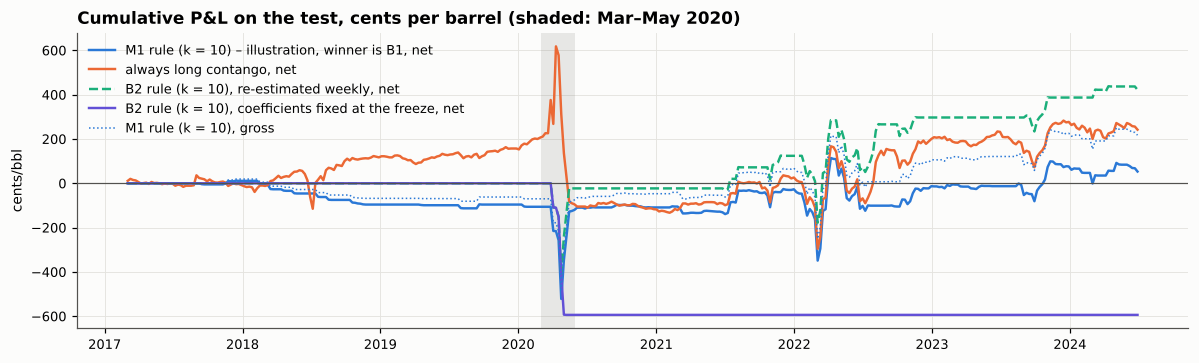


Net P&L (cents) and weeks traded, by period
                                                    before Mar 2020  Mar-May 2020  after May 2020  weeks traded, before Mar 2020  weeks traded, Mar-May 2020  weeks traded, after May 2020
M1 rule (k = 10) – illustration, winner is B1                  -106           -14             173                             18                           8                           120
always long contango                                            206          -301             337                            157                          13                           213
B2 rule (k = 10), re-estimated weekly                             0           -23             445                              0                           6                            55
B2 rule (k = 10), coefficients fixed at the freeze                0          -594               0                              0                           4                             0

B2 coefficient on c

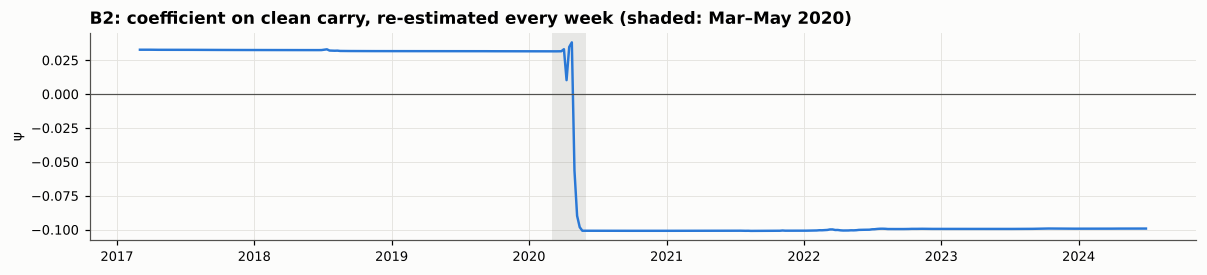

In [41]:
k = FZ["k_cents"]; sigm = FZ["signal_model"]; idx = F_TEST.index
RULES = {f"{sigm} rule (k = {k:g})" + (" – illustration, winner is B1" if FZ["winner"] == "B1" else ""): trade(idx, forecast=F_TEST[sigm], k=k),
         "always long contango": trade(idx, position=np.ones(len(idx)))}
if sigm != "B2":
    RULES[f"B2 rule (k = {k:g}), re-estimated weekly"] = trade(idx, forecast=F_TEST["B2"], k=k)
    r_b2f = ols(TV, "y", FZ["b2_terms"])                                  # coefficients as known at the freeze
    f_b2f = r_b2f.params["const"] + (DF.loc[idx, FZ["b2_terms"]].astype(float) * r_b2f.params[FZ["b2_terms"]]).sum(axis=1)
    RULES[f"B2 rule (k = {k:g}), coefficients fixed at the freeze"] = trade(idx, forecast=f_b2f, k=k)
MAIN = list(RULES)[0]
def thin_rule(P):
    """Hit rate and Sharpe mean nothing on a handful of trades: not quoted below MIN_TRADED traded weeks."""
    P = P.copy(); thin = P["weeks traded"] < MIN_TRADED
    P.loc[thin, ["hit rate when traded, %", "Sharpe (mean/sd x sqrt 52)"]] = np.nan
    P["note"] = np.where(thin, f"fewer than {MIN_TRADED} traded weeks: hit rate and Sharpe not quoted", "")
    return P


P_TEST = save_table(thin_rule(pd.DataFrame({n: pnl_stats(t) for n, t in RULES.items()}).T), "t9_trading_test")
P_TEST_X = save_table(thin_rule(pd.DataFrame({n: pnl_stats(t, NO20) for n, t in RULES.items()}).T), "t9_trading_test_ex2020")
print("TEST, all 383 weeks (headline), cents per barrel, 1 cent per side"); print(P_TEST.T.to_string(float_format=lambda v: f"{v:.2f}"))
print("\nTEST without Mar-May 2020 (sensitivity, post-test)"); print(P_TEST_X.T.to_string(float_format=lambda v: f"{v:.2f}"))
sens = pd.DataFrame({f"{c:g} cent/side": {n: (trade(idx, position=t.pos.values, cost=c).net.sum()) for n, t in RULES.items()} for c in COST_SENS})
print("\nNet P&L (cents) by cost assumption"); print(sens.to_string(float_format=lambda v: f"{v:.1f}"))
pos_share = RULES[MAIN].pos.value_counts(normalize=True).reindex([1.0, 0.0, -1.0]).fillna(0) * 100
print(f"\n{MAIN}: long contango {pos_share[1.0]:.0f}% of weeks, flat {pos_share[0.0]:.0f}%, short {pos_share[-1.0]:.0f}%")

fig, ax = plt.subplots(figsize=(11, 3.4))
tf_ = DF.loc[idx, "target_friday"]
for (n, t), col in zip(RULES.items(), [C["blue"], C["orange"], C["aqua"], C["violet"]]):
    ax.plot(tf_, t.net.cumsum(), color=col, label=n + ", net", ls="--" if "re-estimated" in n else "-")
ax.plot(tf_, RULES[MAIN].gross.cumsum(), color=C["blue"], lw=1, ls=":", label=MAIN.split(" –")[0] + ", gross")
ax.axhline(0, color=C["mute"], lw=0.8); ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2020-05-31"), color=C["mute"], alpha=0.12, lw=0)
ax.set_title("Cumulative P&L on the test, cents per barrel (shaded: Mar–May 2020)"); ax.set_ylabel("cents/bbl"); ax.legend(loc="upper left")
savefig("11_trading_pnl_test")

# Where does each rule's P&L come from? Before, during and after Mar-May 2020
per = pd.cut(pd.DatetimeIndex(tf_.values), [pd.Timestamp("2000-01-01"), pd.Timestamp("2020-02-29"), pd.Timestamp("2020-05-31"), pd.Timestamp("2030-01-01")],
             labels=["before Mar 2020", "Mar-May 2020", "after May 2020"])
BYPER = save_table(pd.DataFrame({n: pd.concat([t.net.groupby(np.asarray(per)).sum(), (t.pos != 0).groupby(np.asarray(per)).sum().add_prefix("weeks traded, ")])
                                 for n, t in RULES.items()}).T[["before Mar 2020", "Mar-May 2020", "after May 2020",
                                 "weeks traded, before Mar 2020", "weeks traded, Mar-May 2020", "weeks traded, after May 2020"]], "t9_trading_by_period")
print("\nNet P&L (cents) and weeks traded, by period"); print(BYPER.to_string(float_format=lambda v: f"{v:.0f}"))

# The B2 coefficient on carry, re-estimated each week through the test
yv, A2 = DF.y.values, np.c_[np.ones(len(DF)), DF[FZ["b2_terms"]].values.astype(float)]
PSI_PATH = pd.Series([np.linalg.lstsq(A2[:i], yv[:i], rcond=None)[0][1] for i in DF.index.get_indexer(idx)], index=tf_.values)
flip = PSI_PATH.diff().abs().idxmax()
print(f"\nB2 coefficient on carry: {PSI_PATH[PSI_PATH.index < flip].iloc[-1]:+.3f} the week before {pd.Timestamp(flip).date()}, {PSI_PATH[flip]:+.3f} that week, {PSI_PATH.iloc[-1]:+.3f} at the end of the test.")
fig, ax = plt.subplots(figsize=(11, 2.6))
ax.plot(PSI_PATH.index, PSI_PATH.values, color=C["blue"]); ax.axhline(0, color=C["mute"], lw=0.8)
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2020-05-31"), color=C["mute"], alpha=0.12, lw=0)
ax.set_title("B2: coefficient on clean carry, re-estimated every week (shaded: Mar–May 2020)"); ax.set_ylabel("ψ")
savefig("12_b2_coefficient_path_test")

### 9.0 Post-test check: does a stretched spread pull back inside the test window?
The expanding-window ψ above mixes 25 years of data, so one extreme week can move it. Here the same regression (next week's earnable change on
today's clean carry, Newey–West errors) is run separately on each period. This was done after the test had been seen.


In [42]:
def psi_period(mask):
    d = DF[mask]; r = ols(d, "y", ["carry_clean"])
    return {"psi": r.params["carry_clean"], "HAC t": r.tvalues["carry_clean"], "weeks": len(d)}


tfD = DF.target_friday
PSI_PER = pd.DataFrame({"training": psi_period(TR), "validation": psi_period(VA),
                        "test, all weeks": psi_period(TE), "test without Mar-May 2020": psi_period(TE & (DF.ev_2020 == 0)),
                        "test before Mar 2020 (Mar 2017 - Feb 2020)": psi_period(TE & (tfD <= "2020-02-29")),
                        "test after May 2020 (Jun 2020 - Jun 2024)": psi_period(TE & (tfD >= "2020-06-01"))}).T
PSI_PER = save_table(PSI_PER, "t9_psi_by_period")
print("Slope of next week's earnable change on today's clean carry, by period (post-test)")
print(PSI_PER.to_string(formatters={"psi": "{:+.3f}".format, "HAC t": "{:.2f}".format, "weeks": "{:.0f}".format}))

# How much of the expanding-window estimate is one week? Same fit as the last point of the path above, with and without the week to 24 Apr 2020.
last = DF.index.get_loc(idx[-1]); big = DF.index.get_loc(pd.Timestamp("2020-04-17")); rows_ = np.r_[0:big, big + 1:last]
psi_wo = np.linalg.lstsq(A2[rows_], yv[rows_], rcond=None)[0][1]
print(f"\nExpanding-window psi at the end of the test: {PSI_PATH.iloc[-1]:+.3f}; leaving out the single week to 24 Apr 2020: {psi_wo:+.3f}.")
pre, post = PSI_PER.loc["test before Mar 2020 (Mar 2017 - Feb 2020)"], PSI_PER.loc["test after May 2020 (Jun 2020 - Jun 2024)"]
if pre.psi < 0 and pre["HAC t"] < -1.96:
    print(f"-> The April 2020 week explains when the expanding estimate changed sign, but not the pull-back itself: the slope is {pre.psi:+.3f} (t {pre['HAC t']:.2f}) "
          f"before March 2020 and {post.psi:+.3f} (t {post['HAC t']:.2f}) after May 2020.")
    print("   Both t-statistics pass the ordinary 5% value (-1.96) but not the Dickey-Fuller value of -2.86 named in Section 2.2, which is the cautious bar here.")
    print("   It is absent in training and validation, was not the frozen model and was found after the test: a hypothesis for future work, not a result.")
else:
    print("-> No significant pull-back inside the test window before March 2020: the change in psi is carried by the 2020 weeks.")


Slope of next week's earnable change on today's clean carry, by period (post-test)
                                              psi HAC t weeks
training                                   +0.041  1.32   765
validation                                 -0.010 -0.45   382
test, all weeks                            -0.358 -3.72   383
test without Mar-May 2020                  -0.063 -2.31   370
test before Mar 2020 (Mar 2017 - Feb 2020) -0.090 -2.18   157
test after May 2020 (Jun 2020 - Jun 2024)  -0.066 -1.98   213

Expanding-window psi at the end of the test: -0.099; leaving out the single week to 24 Apr 2020: -0.021.
-> The April 2020 week explains when the expanding estimate changed sign, but not the pull-back itself: the slope is -0.090 (t -2.18) before March 2020 and -0.066 (t -1.98) after May 2020.
   Both t-statistics pass the ordinary 5% value (-1.96) but not the Dickey-Fuller value of -2.86 named in Section 2.2, which is the cautious bar here.
   It is absent in training and valid

### 9.1 How sure are these numbers? Block bootstrap
A total P&L is one number from one stretch of history. To see how much it could have differed by luck, the weekly net P&L of each rule is resampled
5,000 times. Weeks are drawn in **blocks of 8 consecutive weeks** (wrapping around the end), not one at a time, so that quiet and violent stretches stay together
as they do in the data. Each resample gives a total P&L and a Sharpe ratio; the middle 95% of them is the interval.

If the interval for the total includes zero, the rule's profit cannot be told apart from luck. The block length and the number of resamples were set in Section 0.
The resampling takes each rule's weekly P&L as given, so it measures luck in the weeks, not uncertainty in the model's coefficients.

**Reading the Sharpe ratio.** It says how much was earned per unit of risk, not whether the profit was luck: read it with its interval.
Weekly P&L here has fat tails (see "worst week" above), so the Sharpe ratio understates the risk of a crash. A rule with fewer than 26 traded
weeks is not bootstrapped.


Block bootstrap, 5000 resamples, blocks of 8 weeks. TEST, all 383 weeks
                                                   net (cents)  95% low 95% high chance of a loss, % Sharpe Sharpe 95% low Sharpe 95% high                                          note
M1 rule (k = 10) – illustration, winner is B1            53.00  -858.03  1038.00               45.78   0.04          -0.66            0.69                                              
always long contango                                    242.00 -1211.07  1525.10               34.02   0.12          -0.57            0.93                                              
B2 rule (k = 10), re-estimated weekly                   422.00  -526.00  1404.02               18.54   0.28          -0.37            0.99                                              
B2 rule (k = 10), coefficients fixed at the freeze     -594.00      NaN      NaN                 NaN    NaN            NaN             NaN  too few trades to bootstrap (4 traded weeks)

TE

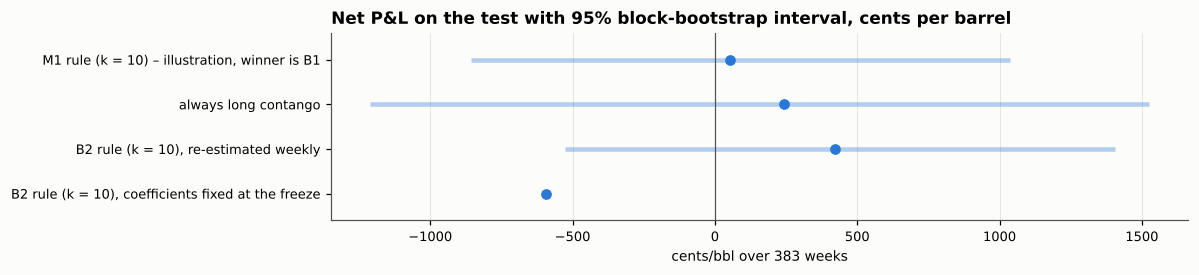

In [43]:
def block_bootstrap(x, B=BOOT_B, block=BOOT_BLOCK, seed=SEED):
    """Circular moving-block bootstrap of a weekly P&L series. Returns the resampled totals and Sharpe ratios."""
    x = np.asarray(x, float); n = len(x); rng = np.random.default_rng(seed)
    starts = rng.integers(0, n, size=(B, int(np.ceil(n / block))))
    take = ((starts[:, :, None] + np.arange(block)[None, None, :]) % n).reshape(B, -1)[:, :n]
    S = x[take]
    sd = S.std(axis=1, ddof=1)
    return S.sum(axis=1), np.where(sd > 0, S.mean(axis=1) / np.where(sd > 0, sd, 1) * np.sqrt(52), np.nan)


def boot_row(tr):
    net = tr.net.values; n_tr = int((tr.pos != 0).sum())
    if n_tr < MIN_TRADED:                                  # a handful of trades cannot be resampled meaningfully
        return {"net (cents)": net.sum(), "95% low": np.nan, "95% high": np.nan, "chance of a loss, %": np.nan, "Sharpe": np.nan,
                "Sharpe 95% low": np.nan, "Sharpe 95% high": np.nan, "note": f"too few trades to bootstrap ({n_tr} traded weeks)"}
    tot, sh = block_bootstrap(net)
    return {"net (cents)": net.sum(), "95% low": np.percentile(tot, 2.5), "95% high": np.percentile(tot, 97.5), "chance of a loss, %": 100 * (tot < 0).mean(),
            "Sharpe": net.mean() / net.std() * np.sqrt(52), "Sharpe 95% low": np.nanpercentile(sh, 2.5), "Sharpe 95% high": np.nanpercentile(sh, 97.5), "note": ""}


BOOT = save_table(pd.DataFrame({n: boot_row(t) for n, t in RULES.items()}).T, "t9_bootstrap_test")
BOOT_X = save_table(pd.DataFrame({n: boot_row(t[NO20.values]) for n, t in RULES.items()}).T, "t9_bootstrap_test_ex2020")
print(f"Block bootstrap, {BOOT_B} resamples, blocks of {BOOT_BLOCK} weeks. TEST, all 383 weeks"); print(BOOT.to_string(float_format=lambda v: f"{v:.2f}"))
print("\nTEST without Mar-May 2020 (sensitivity, post-test; the remaining weeks joined end to end)"); print(BOOT_X.to_string(float_format=lambda v: f"{v:.2f}"))
BOOT_SIG = [n for n in BOOT.index if BOOT.loc[n, "95% low"] > 0]
print("\n->", "No rule has a 95% interval above zero: none of these profits (or Sharpe ratios) can be told apart from luck." if not BOOT_SIG
      else f"95% interval above zero on all weeks: {BOOT_SIG}.")

fig, ax = plt.subplots(figsize=(11, 2.6))
yy = np.arange(len(BOOT))[::-1]
ax.hlines(yy, BOOT["95% low"].astype(float), BOOT["95% high"].astype(float), color=C["blue"], lw=3, alpha=0.35)
ax.plot(BOOT["net (cents)"].astype(float), yy, "o", color=C["blue"])
ax.axvline(0, color=C["mute"], lw=0.8); ax.set_yticks(yy); ax.set_yticklabels(BOOT.index); ax.set_ylim(-0.6, len(BOOT) - 0.4)
ax.set_title("Net P&L on the test with 95% block-bootstrap interval, cents per barrel"); ax.set_xlabel("cents/bbl over 383 weeks"); ax.grid(axis="y", visible=False)
savefig("13_bootstrap_pnl_test")


### 9.2 The numbers for the trader message
Version A is allowed only if the frozen winner beats B1 on the test **and** the rule is positive after costs. Otherwise version B.

In [44]:
net_main = P_TEST.loc[MAIN, "net (cents)"]
VERSION = "A" if (FZ["winner"] != "B1" and BEATS and net_main > 0) else "B"
dte = DF[TE]
print(f"MESSAGE VERSION {VERSION}\n")
print(f"typical weekly move of the held spread (test): median |move| {100 * dte.y_usd.abs().median():.0f} cents, sd {100 * dte.y_usd.std():.0f} cents "
      f"(sd without Mar-May 2020: {100 * dte.y_usd[dte.ev_2020 == 0].std():.0f} cents)")
print(f"last-day effect: median |daily spread change| {100 * around['L']:.0f} cents on the final session vs {100 * around['L-3']:.0f} on a normal day "
      f"({around['L'] / around['L-3']:.1f}x)")
if VERSION == "A":
    cw = C_TEST.loc[f"{FZ['winner']} vs B1"]
    print(f"forecast error cut vs no change: {100 * cw['R2_OS']:.1f}% (MSE), one-sided p = {cw['one-sided p']:.3f}")
    print(f"rule: {P_TEST.loc[MAIN, 'net per week']:.2f} cents/bbl per week after costs, worst week {P_TEST.loc[MAIN, 'worst week']:.0f} cents")
    print(f"stock surprise: 5 million bbl above normal -> {r_tv.params.get(FZ['surprise_version'], np.nan) * 5000 * 70:+.1f} cents/bbl next week at $70 oil")
else:
    print(f"no model beat 'no change' by the rule fixed in advance (winner on validation: {FZ['winner']}); "
          f"the {sigm} signal was {'tradeable' if FZ['tradeable_on_validation'] else 'not tradeable'} on validation.")
    print(f"illustrative {sigm} rule: {net_main:+.0f} cents net over 383 weeks ({P_TEST.loc[MAIN, 'net per week']:+.2f} per week), worst week {P_TEST.loc[MAIN, 'worst week']:.0f} cents")

# Why M1 failed on the test (post-test). Mar-May 2020 is left out so that ordinary conditions can be seen.
ORDER = ["ordinary week", "week ending in the last 3 sessions", "roll week"]
wk_type = pd.Series(np.where(DF.roll_week == 1, ORDER[2], np.where(DF.window_week == 1, ORDER[1], ORDER[0])), index=DF.index)
calm = (DF.ev_2020 == 0).values
CAL = (100 * DF.y_usd[calm]).groupby([wk_type[calm].values, DF.split[calm].values]).mean().unstack()[["train", "validation", "test"]]
CAL = save_table(CAL.loc[ORDER], "t9_calendar_pattern")
print("\n1. Average weekly move of the held spread, cents/bbl (positive = contango widens)"); print(CAL.to_string(float_format=lambda v: f"{v:+.1f}"))
w_ = CAL.loc[ORDER[1]]
print(f"-> weeks ending in the last 3 sessions averaged {w_['train']:+.1f} cents in training, {w_['validation']:+.1f} on validation and {w_['test']:+.1f} on the test: "
      + ("the calendar pattern M1 learned did not last." if np.sign(w_['train']) != np.sign(w_['test']) else "the sign held."))

# Where is M1's extra error against no change? Frozen forecasts, test without Mar-May 2020.
dx = DF.loc[F_TEST.index][NO20.values]; fx = F_TEST.M1[NO20.values]; tx = wk_type.loc[dx.index]
act_c, f_c = 100 * dx.y_usd, fx * dx.CL1
extra_p = (dx.y - fx) ** 2 - dx.y ** 2
extra_c = (act_c - f_c) ** 2 - act_c ** 2
WHY = pd.DataFrame({"weeks": tx.value_counts(),
                    "share of M1's extra squared error, % (points)": 100 * extra_p.groupby(tx).sum() / extra_p.sum(),
                    "same, % (cents)": 100 * extra_c.groupby(tx).sum() / extra_c.sum(),
                    "M1 forecast, mean cents": f_c.groupby(tx).mean(), "actual, mean cents": act_c.groupby(tx).mean()}).loc[ORDER]
WHY = save_table(WHY, "t9_m1_error_by_week_type")
print("\n2. M1 against no change on the test without Mar-May 2020, by type of week"); print(WHY.to_string(float_format=lambda v: f"{v:+.1f}"))
o_, e_, r_ = WHY.loc[ORDER[0]], WHY.loc[ORDER[1]], WHY.loc[ORDER[2]]
sh_p, sh_c = "share of M1's extra squared error, % (points)", "same, % (cents)"
print(f"-> {o_[sh_p]:.0f}% of M1's extra squared error is in ordinary weeks ({o_[sh_c]:.0f}% in cents), where it forecast {o_['M1 forecast, mean cents']:+.1f} cents a week "
      f"against an actual {o_['actual, mean cents']:+.1f}.")
print(f"   M1's constant is estimated in points. CL1 averaged ${DF.CL1[TR].mean():.0f} in training and ${DF.CL1[TE].mean():.0f} on the test, so the same constant is worth more cents.")
# split the scored ordinary-week forecast into its terms, with the coefficients re-estimated each week (rebuilds F_TEST.M1 exactly)
A1 = np.c_[np.ones(len(DF)), DF[FZ["m1_terms"]].values.astype(float)]
parts = pd.DataFrame([A1[i] * np.linalg.lstsq(A1[:i], yv[:i], rcond=None)[0] * DF.CL1.iloc[i] for i in DF.index.get_indexer(dx.index)],
                     index=dx.index, columns=["constant"] + FZ["m1_terms"])
assert np.allclose(parts.sum(axis=1) / dx.CL1, fx), "decomposition does not rebuild the scored M1 forecast"
DRIFT = parts[(tx == ORDER[0]).values].mean()
save_table(pd.DataFrame({"mean cents per ordinary week": pd.concat([DRIFT, pd.Series({"total forecast": DRIFT.sum(), "actual": o_["actual, mean cents"]})])}),
           "t9_m1_ordinary_week_drift")
print(f"   So M1 failed mainly because the drift it forecast in ordinary weeks ({DRIFT.sum():+.1f} cents a week at test prices, of which "
      f"{DRIFT['constant']:+.1f} from the constant and {DRIFT['carry_clean']:+.1f} from carry) was only {o_['actual, mean cents']:+.1f} cents on the test.")
print(f"   Weeks ending in the last 3 sessions are {e_[sh_p]:.0f}% of the extra error and roll weeks {r_[sh_p]:.0f}%: the roll and expiry-window effects are the smaller part.")
print(f"   The fundamentals were not significant in training either (joint F-test p = {FUND_P:.3f}, Section 5.2), so M1 did not fail because inventories stopped working.")


MESSAGE VERSION B

typical weekly move of the held spread (test): median |move| 6 cents, sd 37 cents (sd without Mar-May 2020: 25 cents)
last-day effect: median |daily spread change| 16 cents on the final session vs 5 on a normal day (3.3x)
no model beat 'no change' by the rule fixed in advance (winner on validation: B1); the M1 signal was not tradeable on validation.
illustrative M1 rule: +53 cents net over 383 weeks (+0.14 per week), worst week -265 cents

1. Average weekly move of the held spread, cents/bbl (positive = contango widens)
                                    train  validation  test
ordinary week                        +4.7        +2.7  +1.9
week ending in the last 3 sessions   -6.1        -3.9  +4.6
roll week                            -2.8        +1.6  +0.1
-> weeks ending in the last 3 sessions averaged -6.1 cents in training, -3.9 on validation and +4.6 on the test: the calendar pattern M1 learned did not last.

2. M1 against no change on the test without Mar-May 202

**Section 9 summary** (printed from the data)

In [45]:
print(f"- {MAIN}: gross {P_TEST.loc[MAIN, 'gross (cents)']:+.0f}, net {net_main:+.0f} cents/bbl over {int(P_TEST.loc[MAIN, 'weeks traded'])} traded weeks; "
      f"hit rate {P_TEST.loc[MAIN, 'hit rate when traded, %']:.0f}%; worst week {P_TEST.loc[MAIN, 'worst week']:.0f}; max drawdown {P_TEST.loc[MAIN, 'max drawdown']:.0f}.")
print(f"- Always long contango: net {P_TEST.loc['always long contango', 'net (cents)']:+.0f} cents. Without Mar-May 2020 the rule nets {P_TEST_X.loc['always long contango', 'net (cents)']:+.0f} cents.")
b2n = [n for n in RULES if n.startswith("B2")]
if len(b2n) == 2:
    print(f"- B2 rule: re-estimated weekly {P_TEST.loc[b2n[0], 'net (cents)']:+.0f} cents, of which {BYPER.loc[b2n[0], 'after May 2020']:+.0f} after May 2020 "
          f"({int(BYPER.loc[b2n[0], 'weeks traded, before Mar 2020'])} weeks traded before March 2020); with coefficients fixed at the freeze {P_TEST.loc[b2n[1], 'net (cents)']:+.0f} cents. Neither is the frozen signal.")
    pp = PSI_PER.loc["test before Mar 2020 (Mar 2017 - Feb 2020)"]
    print(f"- Post-test (Section 9.0): slope of y on carry {pp.psi:+.3f} (HAC t {pp['HAC t']:.2f}) on the test before Mar 2020, against {PSI_PER.loc['training', 'psi']:+.3f} in training. "
          "Significant at the ordinary 5% level, not against -2.86. A hypothesis for future work, not a result.")
print(f"- Block bootstrap ({BOOT_B} resamples, {BOOT_BLOCK}-week blocks): {MAIN.split(' –')[0]} net {BOOT.loc[MAIN, 'net (cents)']:+.0f} cents, 95% interval "
      f"{BOOT.loc[MAIN, '95% low']:+.0f} to {BOOT.loc[MAIN, '95% high']:+.0f}, chance of a loss {BOOT.loc[MAIN, 'chance of a loss, %']:.0f}%. "
      + ("No rule's interval excludes zero." if not BOOT_SIG else f"Interval above zero: {BOOT_SIG}."))
print(f"- Trader message: version {VERSION}.")
print("- Limits to state: US-wide stocks, not Cushing; no CL3; costs are assumptions; super-contango weeks are not forecastable; 1990s data quality; "
      "on month-end Fridays the monthly VIX, dollar, crack-spread and yield values enter the same day (Lasso only); earlier group models were scored on parts of the test window (Section 0.1).")
n_csv = len([f for f in os.listdir(OUT) if f.endswith(".csv")]); n_fig = len([f for f in os.listdir(f"{OUT}/figs") if f[:2].isdigit()])
print(f"\nSaved: {CSV}, {FREEZE}, {n_csv} tables/forecast files in {OUT}/, {n_fig} notebook figures in {OUT}/figs/.")

- M1 rule (k = 10) – illustration, winner is B1: gross +217, net +53 cents/bbl over 146 traded weeks; hit rate 50%; worst week -265; max drawdown -534.
- Always long contango: net +242 cents. Without Mar-May 2020 the rule nets +543 cents.
- B2 rule: re-estimated weekly +422 cents, of which +445 after May 2020 (0 weeks traded before March 2020); with coefficients fixed at the freeze -594 cents. Neither is the frozen signal.
- Post-test (Section 9.0): slope of y on carry -0.090 (HAC t -2.18) on the test before Mar 2020, against +0.041 in training. Significant at the ordinary 5% level, not against -2.86. A hypothesis for future work, not a result.
- Block bootstrap (5000 resamples, 8-week blocks): M1 rule (k = 10) net +53 cents, 95% interval -858 to +1038, chance of a loss 46%. No rule's interval excludes zero.
- Trader message: version B.
- Limits to state: US-wide stocks, not Cushing; no CL3; costs are assumptions; super-contango weeks are not forecastable; 1990s data quality; on month-

## Design decisions

1. **Lasso pool.** 18 candidate columns, all listed in Section 3.
2. **Expanding vs rolling.** The rolling window replaces the expanding one only if the Chow test at 28 Nov 2014 rejects at 5% **and** rolling has the lower validation MSE for the signal model.
3. **Wrong signs.** ψ, β₁ and β₂ are the hypotheses, so they stay in M1 whatever their sign; a wrong sign is reported, not hidden.
4. **RESET remedy.** The wide-contango indicator is estimated and shown, but it is added to M1 only if RESET rejects and the indicator is itself significant.
5. **Classical and robust tests.** Chow, RESET and the last-104-weeks stability test are reported in both forms; where they disagree the robust (Newey–West Wald) version is read, because the classical F-tests assume constant variance.
6. **Dickey–Fuller.** Run on the generic carry level and on the held spread (roll-adjusted changes added up), both against −2.86. The regression of *y* on clean carry is not strictly a Dickey–Fuller regression, but carry is persistent and its shocks move with *y*, so a negative ψ is also judged against −2.86 (Section 2.2). Phillips–Perron is run next to ADF in Section 2.1 as a check (it needs the `arch` package); KPSS checks both from the opposite null.
7. **Costs.** One side is charged for each entry and each exit (a flip is two), two more for each roll week a position is held through, and one for the final close-out.
8. **No-trade check.** If no threshold makes money after costs on validation, the signal is marked not tradeable and Section 9 is an illustration only.
9. **Cents conversion.** Forecast in cents = forecast in points × CL1 at Friday *t*. Realised cents = 100 × `y_usd`.
10. **Headline sample.** All 383 test weeks is the headline fixed before the test. The scoring without Mar–May 2020 is a sensitivity check chosen after the test had been seen: those 13 target weeks are left out of the scoring only. The models are still fitted on them afterwards, as they would have been in real time.
11. **Units.** The models are specified in points (% of CL1), fixed before the test. The tables also show the same frozen forecasts converted to cents (forecast × CL1). Section 8.3 (post-test) re-estimates the models on a dollar target to show the conclusion does not depend on the unit; its numbers are not the same thing as the cents columns.
12. **Freeze.** `freeze.json` is written once and never overwritten; a changed setting stops the notebook.
13. **Block bootstrap.** Trading results carry 95% intervals from a circular block bootstrap of each rule's weekly net P&L (5,000 resamples, 8-week blocks, fixed seed).
14. **Comparing forecasts.** One-sided t-test on the weekly difference in squared errors, with Newey–West errors. It needs only a t-test and robust errors. For a larger model against a smaller one nested in it, the plain test leans against the larger model, so "no significant gain" is the cautious reading.
15. **Correct sign.** Always shown next to the share of "up" forecasts and the score of always guessing "up".
16. **Sharpe ratio.** Mean weekly net P&L over its standard deviation, × √52. No risk-free rate is subtracted because a futures spread needs no capital outlay. It is read with its bootstrap interval, it understates crash risk when P&L has fat tails, and it is not quoted for a rule with fewer than 26 traded weeks.
17. **Post-test analyses.** Listed at the top of Section 8. They change no frozen setting and are not evidence for a model.
